$$\large\text{Федеральное государственное бюджетное образовательное учреждение высшего образования}$$
$$\large\textbf{«ФИНАНСОВЫЙ УНИВЕРСИТЕТ ПРИ ПРАВИТЕЛЬСТВЕ РОССИЙСКОЙ ФЕДЕРАЦИИ»}$$
$$\large\textbf{Кафедра искусственного интеллекта}$$
<br>
<br>
<br>
$$\large\text{Курсовой проект по дисциплине "Машинное обучение"}$$
$$\large\text{на тему:}$$
$$\large\text{"Аугментация табличных данных и её влияние на качество на ML-моделей"}$$
<br>
<br>
<br>
<br>
$\large\text{Выполнила:}$ <br>
$\large\text{студентка группы ПМ24-3}$ <br>
$\large\text{факультета информационных}$ <br>
$\large\text{технологий и анализа больших данных}$ <br>
$\large\text{Жаткина В.Р.}$
<br>
<br>
$\large\text{Научный руководитель:}$ <br>
$\large\text{доцент, кандитат технических наук}$ <br>
$\large\text{Андриянов Н.А.}$
<br>
<br>
<br>
<br>
<br>
$$\large\text{2026}$$

## $\Large\textbf{Введение}$

$\Large\textbf{Актуальность:}$
<br>

$\large\text{Ключевой проблемой машинного обучения продолжает оставаться качество и объем данных. Реальные датасеты зачастую содержат либо критически малый объем данных, которого}$
$\large\text{не хватает для качественного обучения моделей, либо сильный дисбаланс классов, который тоже мешает моделям качественно работать. Особенно остро эта проблема}$
$\large\text{стоит для табличных данных, так как это наиболее распространённый формат хранения информации. Таким образом, актуальность данной курсовой работы обусловлена}$
$\large\text{необходимостью систематического анализа того, как аугментация табличных данных влияет на качество моделей машинного обучения.}$

$\Large\textbf{Практическая значимость:}$
<br>

$\large\text{Практическая значимость данной курсовой работы заключается в определении степени эффективности аугментации табличных данных для моделей машинного обучения и}$
$\large\text{нахождении оптимальной конфигурации pipeline.}$

## $\Large\textbf{Выбор датасета и предобработка данных}$

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import *
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import time
from scipy import stats
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix
from yellowbrick.model_selection import LearningCurve
from yellowbrick.classifier import ROCAUC, PrecisionRecallCurve
from sklearn.model_selection import cross_val_score, StratifiedKFold, cross_validate
import warnings
warnings.filterwarnings('ignore')

$\large\text{Для своей работы я выбрала датасет про типы звезд. Он маленького объема, имеет сильный дисбаланс и тем самым отлично подходит для демонстрации того,}$ $\large\text{как аугментация влияет на качество ML-моделей.}$

$\large\text{Задача машинного обучения - множественная классификация, а именно классификация звезд по классам на основе определенных характеристик.}$

$\large\text{Загружаем наш датасет и выводим первые 5 строк:}$

In [ ]:
stars = pd.read_csv('6 class csv.csv')

In [ ]:
stars.head(5)

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M


$\large\text{Выводим основную информацию о датасете и проверяем наличие пропущенных значений:}$

In [ ]:
stars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo)        240 non-null    float64
 2   Radius(R/Ro)            240 non-null    float64
 3   Absolute magnitude(Mv)  240 non-null    float64
 4   Star type               240 non-null    int64  
 5   Star color              240 non-null    object 
 6   Spectral Class          240 non-null    object 
dtypes: float64(3), int64(2), object(2)
memory usage: 13.3+ KB


In [ ]:
stars.isnull().sum()

,0
Temperature (K),0
Luminosity(L/Lo),0
Radius(R/Ro),0
Absolute magnitude(Mv),0
Star type,0
Star color,0
Spectral Class,0


$\large\text{В датасете всего 240 строк, отсутсвуют пропуски и практически все признаки являются числовыми.}$

$\large\text{В качестве таргета выбираем признак "Spectral Class":}$

In [ ]:
target = 'Spectral Class'

y = stars[target]
X = stars.drop(columns=[target])

In [ ]:
y.value_counts().sort_index()

,count
Spectral Class,
A,19
B,46
F,17
G,1
K,6
M,111
O,40


$\large\text{У этого признака достаточно сильный дисбаланс, что отлично подходит для нашей работы.}$

$\large\text{Строим распределение признаков относительно целевого класса:}$

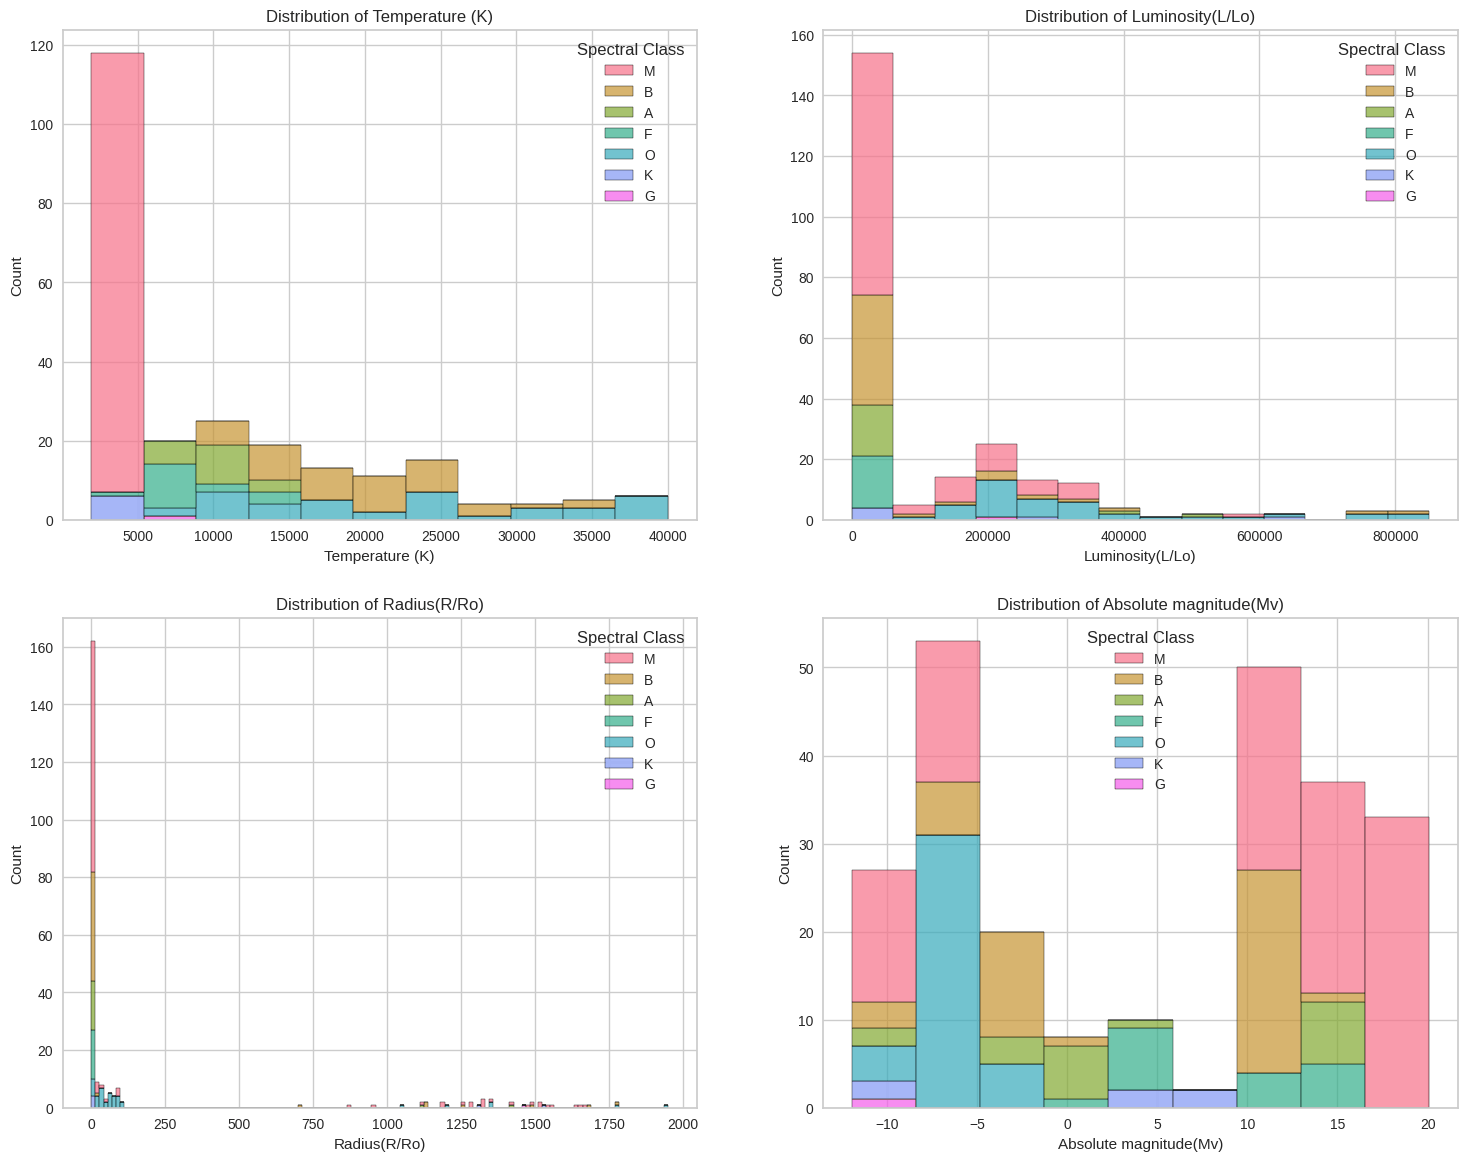

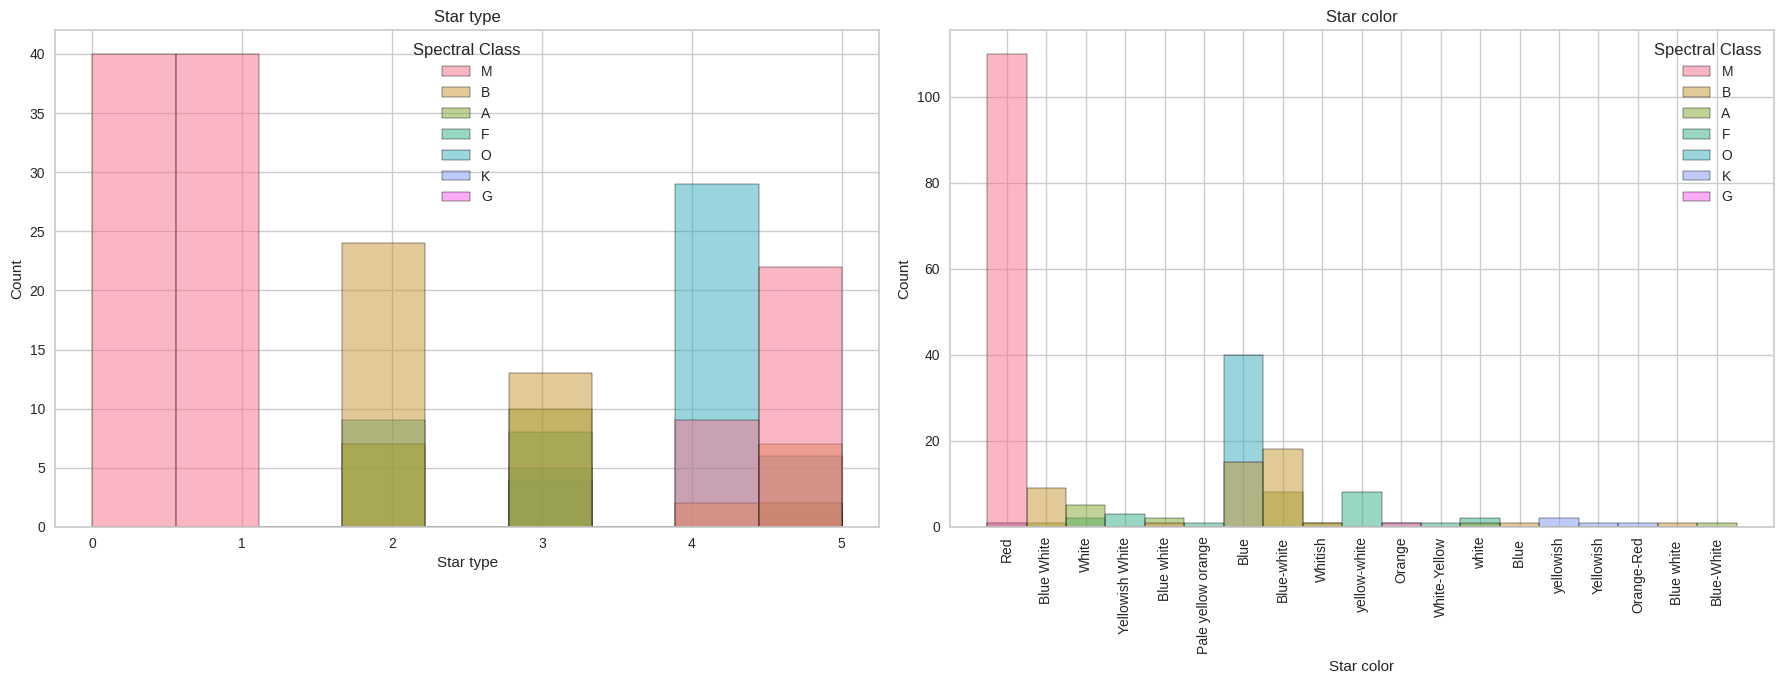

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
numeric_cols = [
    'Temperature (K)',
    'Luminosity(L/Lo)',
    'Radius(R/Ro)',
    'Absolute magnitude(Mv)'
]

for i, col in enumerate(numeric_cols):
    sns.histplot(
        data=stars,
        x=col,
        hue='Spectral Class',
        ax=axes[i//2, i%2],
        multiple='stack',
        alpha=0.7
    )
    axes[i//2, i%2].set_title(f'Distribution of {col}')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.histplot(data=stars, x='Star type', hue='Spectral Class', ax=axes[0])
axes[0].set_title('Star type')

sns.histplot(data=stars, x='Star color', hue='Spectral Class', ax=axes[1])
axes[1].set_title('Star color')
axes[1].tick_params(axis='x', labelrotation=90)

plt.tight_layout()
plt.show()

$\large\text{Графики распределения подтверждают сильный дисбаланс данных.}$

$\large\text{Строим диаграммы типа "Ящик с усами" для выявления выбросов и аномалий:}$

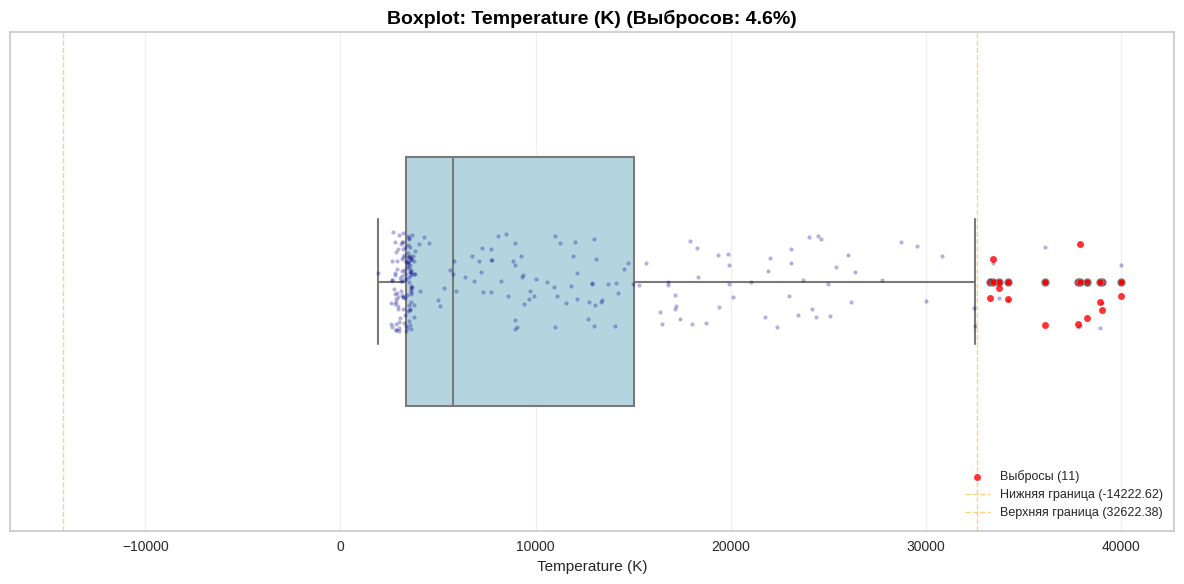

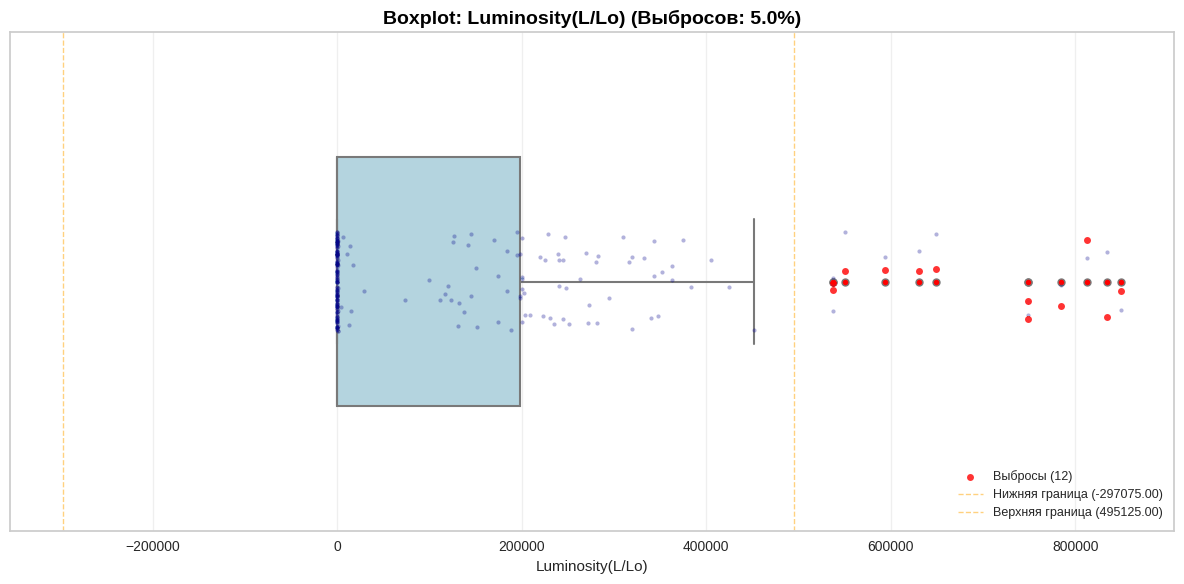

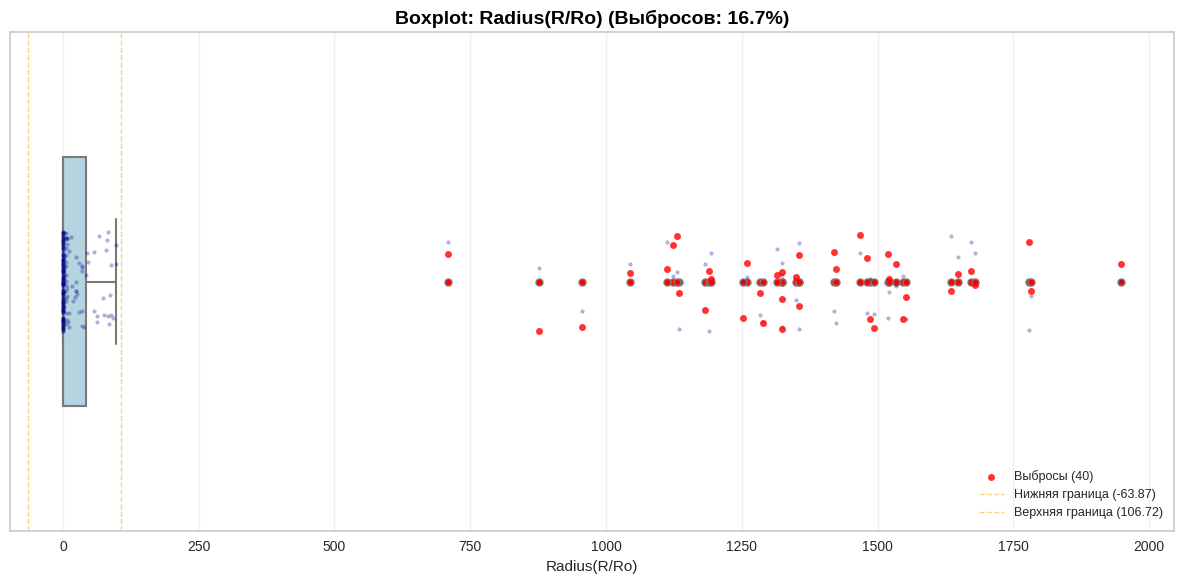

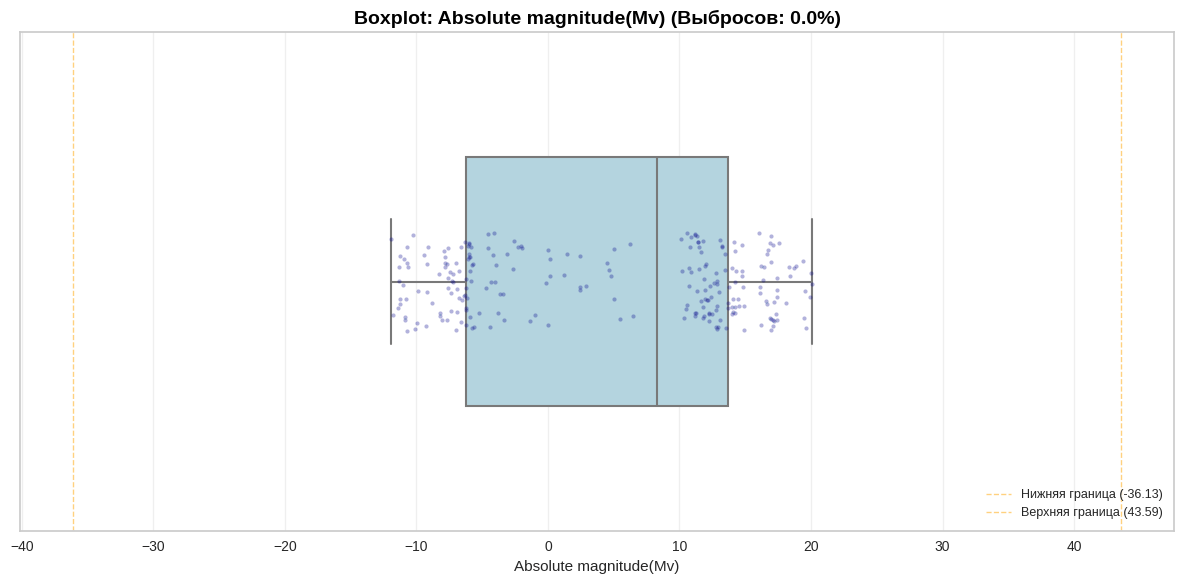

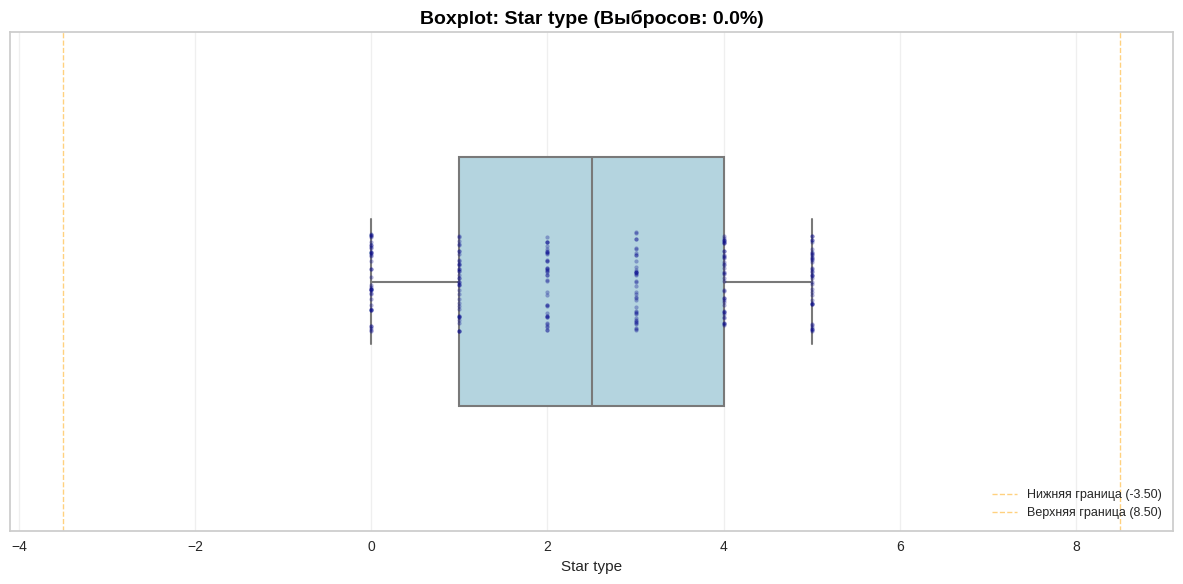

In [ ]:
num_cols = X.select_dtypes(include=[np.number]).columns

for col in num_cols:
    fig, ax = plt.subplots(figsize=(12, 6))
    data_clean = X[col].dropna()

    Q1 = data_clean.quantile(0.25)
    Q3 = data_clean.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data_clean[(data_clean < lower_bound) | (data_clean > upper_bound)]
    outliers_count = len(outliers)
    outliers_percent = (outliers_count / len(data_clean)) * 100

    outliers_indices = X[(X[col] < lower_bound) | (X[col] > upper_bound)].index.tolist()

    sns.boxplot(data=X, x=col, ax=ax, orient='h',
                color='lightblue',
                width=0.5,
                linewidth=1.5,
                fliersize=4,
                flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 5})

    sns.stripplot(data=X, x=col, ax=ax, orient='h', color='darkblue', alpha=0.3, size=3)

    if outliers_count > 0:
        outliers_df = pd.DataFrame({col: outliers})
        sns.stripplot(data=outliers_df, x=col, ax=ax, orient='h', color='red', alpha=0.8, size=5, label=f'Выбросы ({outliers_count})')

    ax.axvline(x=lower_bound, color='orange', linestyle='--', alpha=0.5, linewidth=1, label=f'Нижняя граница ({lower_bound:.2f})')
    ax.axvline(x=upper_bound, color='orange', linestyle='--', alpha=0.5, linewidth=1, label=f'Верхняя граница ({upper_bound:.2f})')

    bbox_props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')

    title_color = 'black'
    ax.set_title(f'Boxplot: {col} (Выбросов: {outliers_percent:.1f}%)',
                 fontsize=14, fontweight='bold', color=title_color)
    ax.set_ylabel('')
    ax.grid(True, alpha=0.3, axis='x')
    ax.set_xlabel(col, fontsize=11)

    ax.legend(loc='lower right', fontsize=9)

    plt.tight_layout()
    plt.show()

$\large\text{По диаграммам видно, что у некоторых признаков есть небольшой процент выбросов, но это не особо критично.}$

$\large\text{Строим корреляционную матрицу:}$

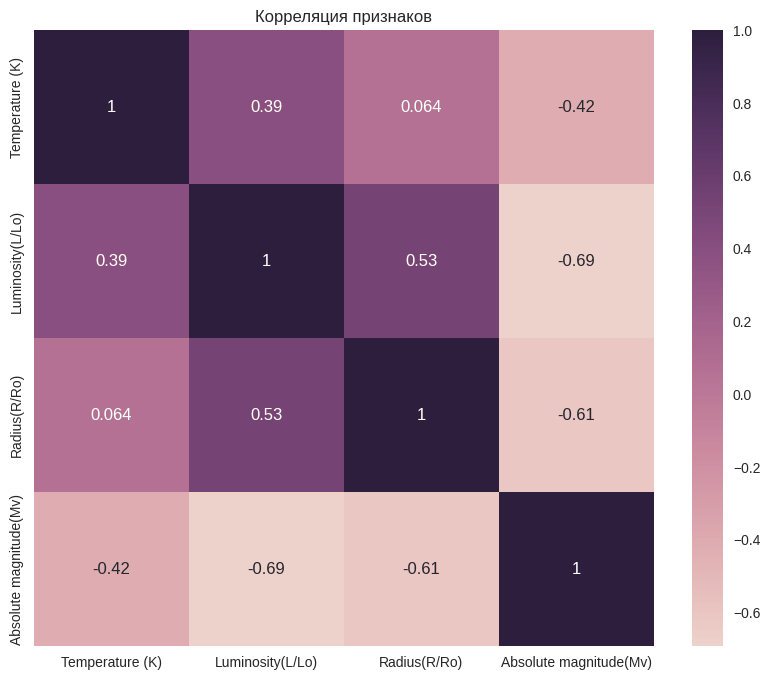

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(X[numeric_cols].corr(), annot=True, cmap=sns.cubehelix_palette(as_cmap=True))
plt.title('Корреляция признаков')
plt.show()

$\large\text{По корреляционной матрице видно, что есть признаки, которые умеренно положительно коррелируют (Luminosity(L/L0) и Radius(R/R0): 53%).}$ <bv>
$\large\text{Также видно, что есть слабая (Luminosity(L/L0) и Temperature(K): 39%) и очень слабая (Radius(R/R0) и Temperature(K): 6,4%) связь между признаками.}$
$\large\text{Отрицательные значения корреляции указывают на обратную зависимость между признаками. В случае нашего датасета это нестрашно, так как данные относятся к физической области}$
$\large\text{и это абсолютно нормально.}$

$\large\text{Для дальнейшей работы убираем из целевой переменной классы G и K, так как они содержат очень мало объектов, и предсказать для их класса будет очень сложно:}$

In [ ]:
mask = (y != 'G') & (y != 'K')
X = X[mask]
y = y[mask]

In [ ]:
y.value_counts().sort_index()

,count
Spectral Class,
A,19
B,46
F,17
M,111
O,40


$\large\text{Проверяем типы данных для признаков:}$

In [ ]:
print(X.dtypes.value_counts())

float64    3
int64      2
object     1
Name: count, dtype: int64


$\large\text{Присутствует один объект типа "object", преобразуем его в числовой формат:}$

In [ ]:
X = X.apply(lambda col: pd.Categorical(col).codes if col.dtype == 'object' else col)

print(X.dtypes.value_counts())

float64    3
int64      2
int8       1
Name: count, dtype: int64


$\large\text{Теперь данные готовы для обучения моделей.}$

## $\Large\textbf{Обучение моделей на данных без аугментации}$

$\large\text{Так как наша целевая переменная является категориальной (названия классов обозначаются латинскими буквами), кодируем ее:}$

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)
y = y_encoded

$\large\text{Разбиваем на тестовую и обучающую выборки:}$

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify=y, random_state=42)

In [ ]:
pd.Series(y_train).value_counts().sort_index()

,count
0,15
1,37
2,13
3,89
4,32


In [ ]:
pd.Series(y_test).value_counts().sort_index()

,count
0,4
1,9
2,4
3,22
4,8


$\large\text{Используем StratifiedKFold, так как у нас классификация и достаточно сильный дисбаланс, этот метод разбиения отлично подходит в данной ситуации:}$

In [ ]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

### $\textbf{LogisticRegression}$

In [ ]:
from sklearn.linear_model import LogisticRegression

$\large\text{Создаем pipeline для Logistic Regression: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
LR_pipeline = make_pipeline(StandardScaler(), LogisticRegression(solver='saga', max_iter=10000, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_LR = cross_validate(
    estimator=LR_pipeline,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_LR.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.8885
train_accuracy: 0.9185
test_f1_weighted: 0.8701
train_f1_weighted: 0.9071
test_precision_weighted: 0.8677
train_precision_weighted: 0.9262
test_recall_weighted: 0.8885
train_recall_weighted: 0.9185


$\large\text{По результатам кросс-валидации модель отлично справляется с предсказанием, отсутсвует пере- и недообучение.}$

$\large\text{Теперь обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

LR = LR_pipeline.fit(X_train, y_train)

finish = time.time()
LR_time = finish - start
print(f'Education time: {LR_time:.6f}')

Education time: 0.017025


$\large\text{Выводим accuracy модели:}$

In [ ]:
LR_score = LR.score(X_test, y_test)
print(f'{LR_score:.4f}')

0.8723


$\large\text{Accuracy равен 0,87, модель показывает хорошие результаты.}$

$\large\text{Выводим матрицу ошибок:}$

<Axes: >

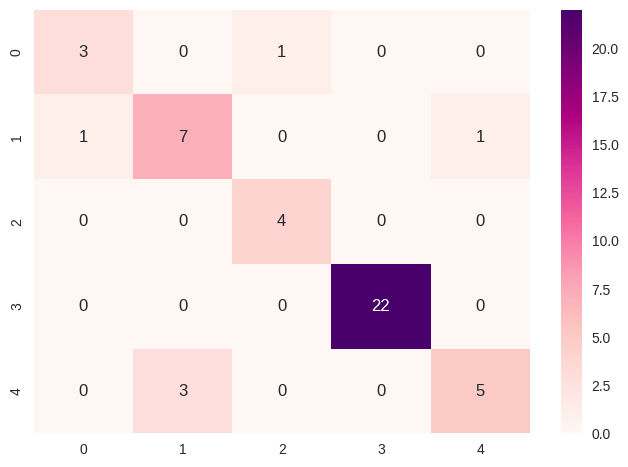

In [ ]:
y_test_pred_LR = LR.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_LR), cmap='RdPu', annot=True, fmt='d')

$\large\text{По матрице ошибок видим, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 1 ошибка,}$ <br>
$\large\text{1 класс - 2 ошибки,}$ <br>
$\large\text{2 класс - нет ошибок,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 8 ошибок}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_LR))

              precision    recall  f1-score   support

           0       0.75      0.75      0.75         4
           1       0.70      0.78      0.74         9
           2       0.80      1.00      0.89         4
           3       1.00      1.00      1.00        22
           4       0.83      0.62      0.71         8

    accuracy                           0.87        47
   macro avg       0.82      0.83      0.82        47
weighted avg       0.88      0.87      0.87        47



$\large\text{По отчету видно, что модель справилась хорошо, но все же некоторые классы (0, 1 и 4) предсказала хуже, чем остальные.}$

$\large\text{Строим кривые ROC-AUC:}$

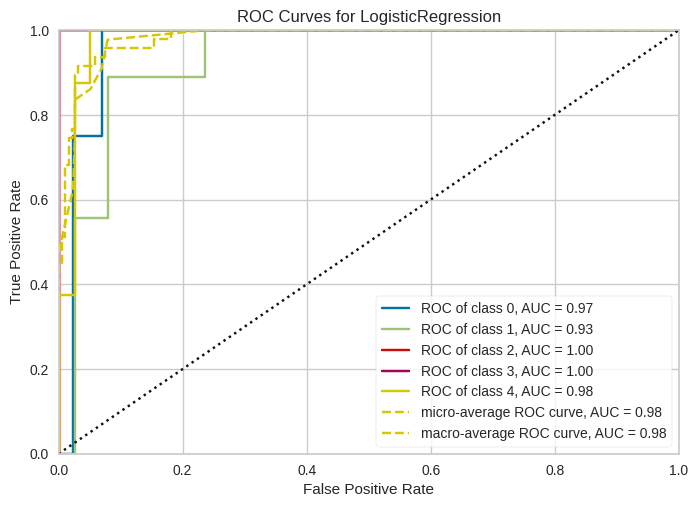

<Axes: title={'center': 'ROC Curves for LogisticRegression'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(LR)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_LR = LR.predict_proba(X_test)
unique_classes = np.unique(y)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_LR[:, i])
    auc_scores[cls] = auc
    print(f"  Класс '{cls}': AUC = {auc:.4f}")

  Класс '0': AUC = 0.9651
  Класс '1': AUC = 0.9327
  Класс '2': AUC = 1.0000
  Класс '3': AUC = 1.0000
  Класс '4': AUC = 0.9808


$\large\text{График показывает, что модель хорошо справилась с предсказанием, все показатели достаточно высокие.}$

$\large\text{Строим кривые Precision-Recall:}$

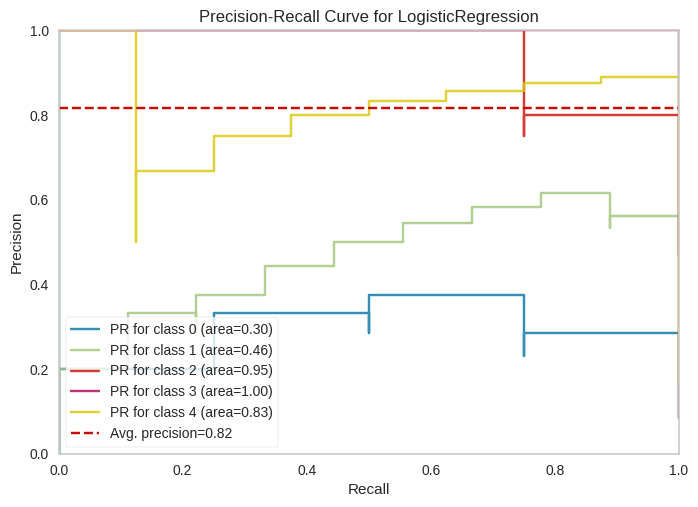

<Axes: title={'center': 'Precision-Recall Curve for LogisticRegression'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    LR,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показал то же самое, что и отчет по классификации: модель плохо справилась с предсказанием первых двух классов.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_LR[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.2729
Класс 1: оптимальный порог = 0.3375
Класс 2: оптимальный порог = 0.3635
Класс 3: оптимальный порог = 0.7944
Класс 4: оптимальный порог = 0.0865


$\large\text{Строим график обучения модели:}$

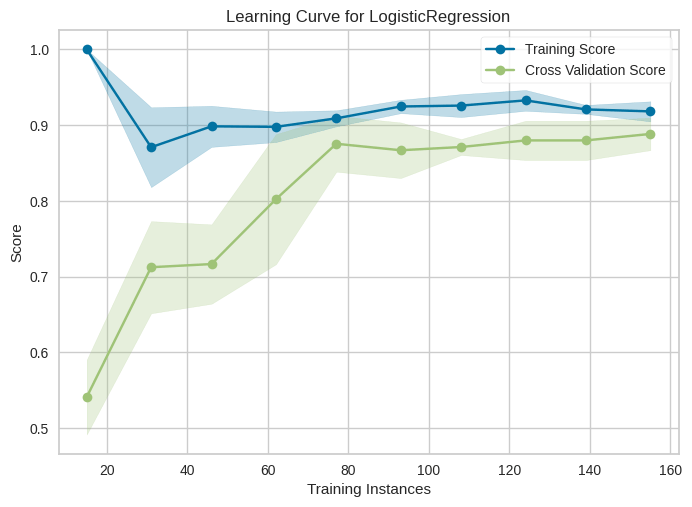

<Axes: title={'center': 'Learning Curve for LogisticRegression'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
from yellowbrick.model_selection import LearningCurve

visualizer = LearningCurve(
    LR_pipeline,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X, y)
visualizer.show()

$\large\text{График обучения показывает, что модель немного переобучена, так как имеется большой разрыв между training score и CV score на малых значениях выборки.}$

### $\textbf{DecisionTreeClassifier}$

In [ ]:
from sklearn.tree import DecisionTreeClassifier

$\large\text{Создаем pipeline для DecisionTreeClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
DTC_pipeline = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=5, random_state=42))

$\large\text{Проводим кросс-вадидация:}$

In [ ]:
cv_results_tree = cross_validate(
    estimator=DTC_pipeline,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_tree.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.8969
train_accuracy: 0.9657
test_f1_weighted: 0.8946
train_f1_weighted: 0.9648
test_precision_weighted: 0.9052
train_precision_weighted: 0.9685
test_recall_weighted: 0.8969
train_recall_weighted: 0.9657


$\large\text{По результатам кросс-валидации наблюдаем не сильный разрыв между обучающей и тестовой точностью модели.}$

$\large\text{Обучаем модель и засекаем время ее обучения.}$

In [ ]:
start = time.time()

tree = DTC_pipeline.fit(X_train, y_train)

finish = time.time()
tree_time = finish - start
print(f'Education time: {tree_time:.6f}')

Education time: 0.007493


$\large\text{Выводим accuracy модели:}$

In [ ]:
tree_score = tree.score(X_test, y_test)
print(f'{tree_score:.4f}')

0.8511


$\large\text{Accuracy равен 0,85, что указывает на то, что модель справилась достаточно хорошо.}$

$\large\text{Выводим матрицу ошибок:}$

<Axes: >

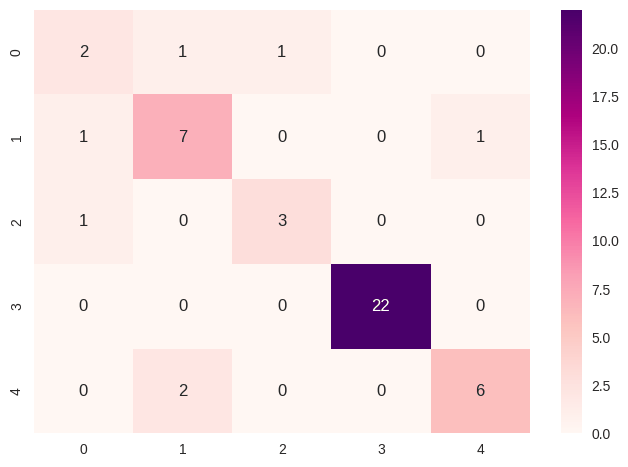

In [ ]:
y_test_pred_tree = tree.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_tree), cmap='RdPu', annot=True)

$\large\text{По матрице ошибок видно, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 2 ошибки,}$ <br>
$\large\text{1 класс - 2 ошибки,}$ <br>
$\large\text{2 класс - 1 ошибка,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 2 ошибки}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_tree))

              precision    recall  f1-score   support

           0       0.50      0.50      0.50         4
           1       0.70      0.78      0.74         9
           2       0.75      0.75      0.75         4
           3       1.00      1.00      1.00        22
           4       0.86      0.75      0.80         8

    accuracy                           0.85        47
   macro avg       0.76      0.76      0.76        47
weighted avg       0.85      0.85      0.85        47



$\large\text{По отчету видно, что модель очень плохо справилась с предсказанием принадлежности к классу 0 и чуть лучше к классам 1 и 2.}$

$\large\text{Строим кривые ROC-AUC:}$

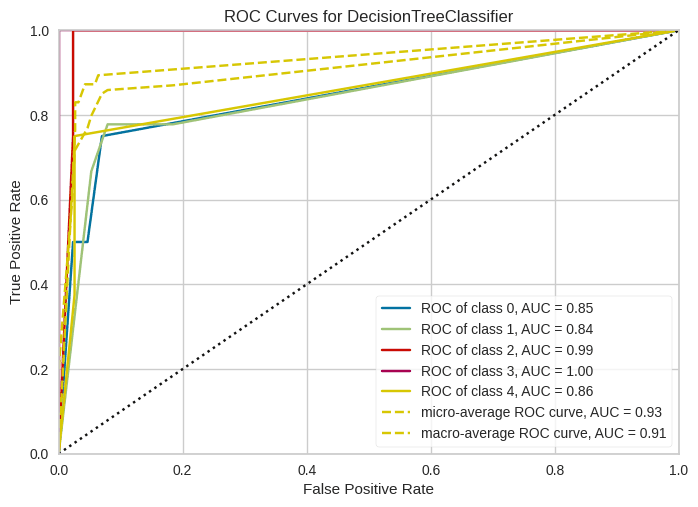

<Axes: title={'center': 'ROC Curves for DecisionTreeClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(tree)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_tree = tree.predict_proba(X_test)
unique_classes = np.unique(y)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_tree[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.8459
Класс '1': AUC = 0.8436
Класс '2': AUC = 0.9855
Класс '3': AUC = 1.0000
Класс '4': AUC = 0.8574


$\large\text{График показывает, что в целом модель хорошо справилась с предсказанием, но и не совсем идеально.}$

$\large\text{Строим кривые Precision-Recall:}$

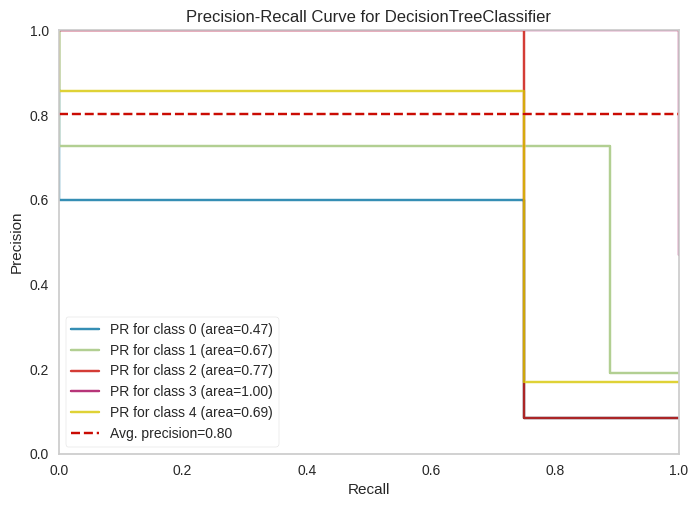

<Axes: title={'center': 'Precision-Recall Curve for DecisionTreeClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    tree,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{Здесь видим, что модель плохо справляется с предсказанием принадлежности ко всем классам, кроме 3.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_tree[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.4000
Класс 1: оптимальный порог = 0.6000
Класс 2: оптимальный порог = 0.1667
Класс 3: оптимальный порог = 1.0000
Класс 4: оптимальный порог = 0.8000


$\large\text{Строим график обучения модели:}$

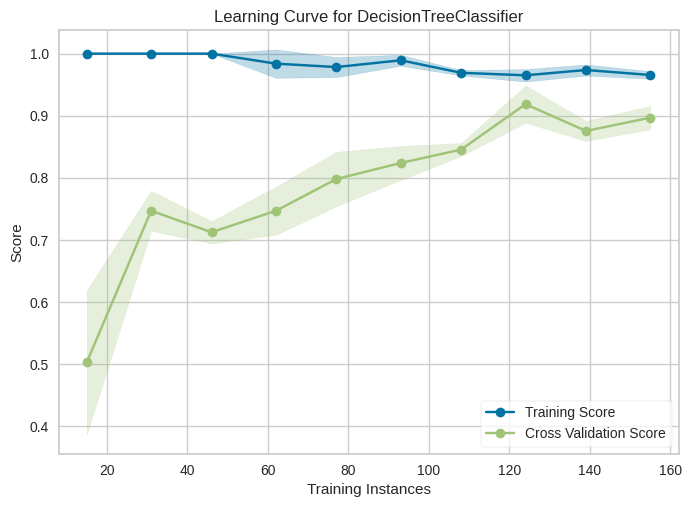

<Axes: title={'center': 'Learning Curve for DecisionTreeClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    DTC_pipeline,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X, y)
visualizer.show()

$\large\text{График обучения показывает, что модель переобучена, так как имеется большой разрыв между training score и CV score на малых значениях выборки.}$

### $\textbf{KNeighborsClassifier}$

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

$\large\text{Создаем pipeline для KNeighborsClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
KNC_pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_knc = cross_validate(
    estimator=KNC_pipeline,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_knc.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.8799
train_accuracy: 0.9185
test_f1_weighted: 0.8726
train_f1_weighted: 0.9136
test_precision_weighted: 0.8786
train_precision_weighted: 0.9181
test_recall_weighted: 0.8799
train_recall_weighted: 0.9185


$\large\text{По результатам кросс-валидации пере- и недообучение отсутсвует.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

knc = KNC_pipeline.fit(X_train, y_train)

finish = time.time()
knc_time = finish - start
print(f'Education time: {knc_time:.6f}')

Education time: 0.005864


$\large\text{Выводим accuracy модели:}$

In [ ]:
knc_score = knc.score(X_test, y_test)
print(f'{knc_score:.4f}')

0.8298


$\large\text{Accuracy равен 0,83, что говорит о том, что модель в принципе хорошо справляется с предсказанием.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

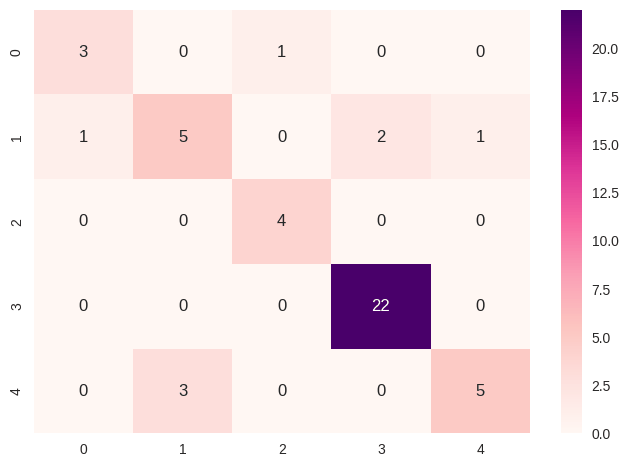

In [ ]:
y_test_pred_knc = knc.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_knc), cmap='RdPu', annot=True)

$\large\text{Матрица ошибок показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 1 ошибка,}$ <br>
$\large\text{1 класс - 4 ошибки,}$ <br>
$\large\text{2 класс - нет ошибок,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 ошибки - 3 ошибки}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_knc))

              precision    recall  f1-score   support

           0       0.75      0.75      0.75         4
           1       0.62      0.56      0.59         9
           2       0.80      1.00      0.89         4
           3       0.92      1.00      0.96        22
           4       0.83      0.62      0.71         8

    accuracy                           0.83        47
   macro avg       0.78      0.79      0.78        47
weighted avg       0.82      0.83      0.82        47



$\large\text{Отчет показывает, что модель хуже справилась с предсказанием 0, 1 и 4 классов.}$

$\large\text{Строим кривые ROC-AUC:}$

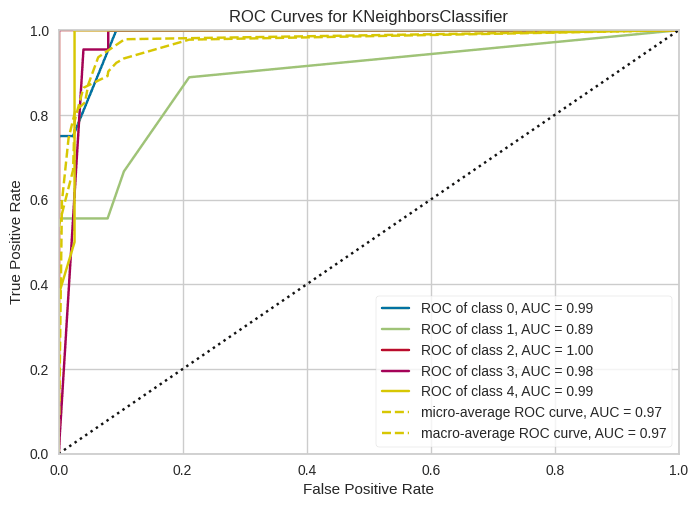

<Axes: title={'center': 'ROC Curves for KNeighborsClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(knc)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_knc = knc.predict_proba(X_test)
unique_classes = np.unique(y)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_knc[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.9855
Класс '1': AUC = 0.8874
Класс '2': AUC = 1.0000
Класс '3': AUC = 0.9773
Класс '4': AUC = 0.9856


$\large\text{График показывает, что модель достаточно хорошо справилась с предсказанием принадлежности к классам.}$

$\large\text{Строим кривые Precision-Recall:}$

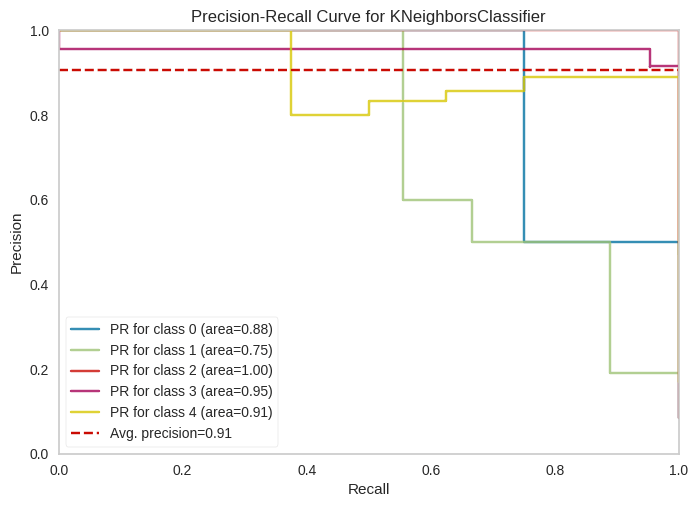

<Axes: title={'center': 'Precision-Recall Curve for KNeighborsClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    knc,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель чуть хуже справилась с предсказанием 1 класса.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_knc[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.2857
Класс 1: оптимальный порог = 0.1429
Класс 2: оптимальный порог = 0.7143
Класс 3: оптимальный порог = 0.7143
Класс 4: оптимальный порог = 0.2857


$\large\text{Строим график обучения модели:}$

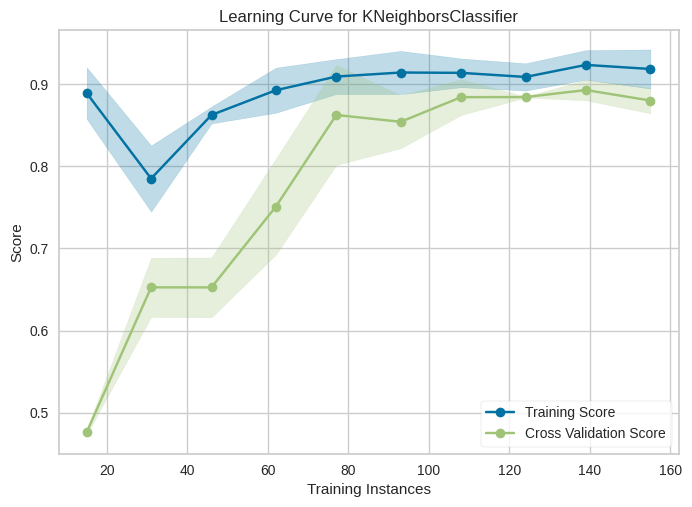

<Axes: title={'center': 'Learning Curve for KNeighborsClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    KNC_pipeline,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X, y)
visualizer.show()

$\large\text{График обучения показывает, что модель умеренно переобучена, так как имеется большой разрыв между training score и CV score на малых значениях выборки.}$

### $\textbf{MLPClassifier}$

In [ ]:
from sklearn.neural_network import MLPClassifier

$\large\text{Создаем pipeline для MLPClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
MLPC_pipeline = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(100, 50, 25, 5), max_iter=10000, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_mlp = cross_validate(
    estimator=MLPC_pipeline,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_mlp.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9315
train_accuracy: 0.9914
test_f1_weighted: 0.9310
train_f1_weighted: 0.9914
test_precision_weighted: 0.9415
train_precision_weighted: 0.9917
test_recall_weighted: 0.9315
train_recall_weighted: 0.9914


$\large\text{По результатам кросс-валидации модель очень хорошо справилась с предсказанием принадлежности к классам, пере- и недообучение отсутствует.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

mlp = MLPC_pipeline.fit(X_train, y_train)

finish = time.time()
mlp_time = finish - start
print(f'Education time: {mlp_time:.6f}')

Education time: 1.598972


$\large\text{Выводим accuracy модели:}$

In [ ]:
mlp_score = mlp.score(X_test, y_test)
print(f'{mlp_score:.4f}')

0.8723


$\large\text{Accuracy равен 0,87, что говорит о том, что модель достаточно хорошо справилась с предсказанием.}$

$\large\text{Выводим матрицу ошибок:}$

<Axes: >

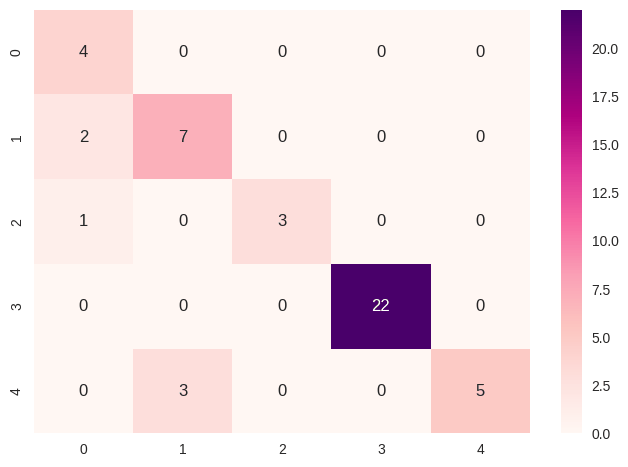

In [ ]:
y_test_pred_mlp = mlp.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_mlp), cmap='RdPu', annot=True)

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - нет ошибок,}$ <br>
$\large\text{1 класс - 2 ошибки,}$ <br>
$\large\text{2 класс - 1 ошибка,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 3 ошибки}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_mlp))

              precision    recall  f1-score   support

           0       0.57      1.00      0.73         4
           1       0.70      0.78      0.74         9
           2       1.00      0.75      0.86         4
           3       1.00      1.00      1.00        22
           4       1.00      0.62      0.77         8

    accuracy                           0.87        47
   macro avg       0.85      0.83      0.82        47
weighted avg       0.91      0.87      0.87        47



$\large\text{Отчет показывает, что модель предсказывает 0, 1 и 4 классы хуже, чем остальные.}$

$\large\text{Строим кривые ROC-AUC:}$

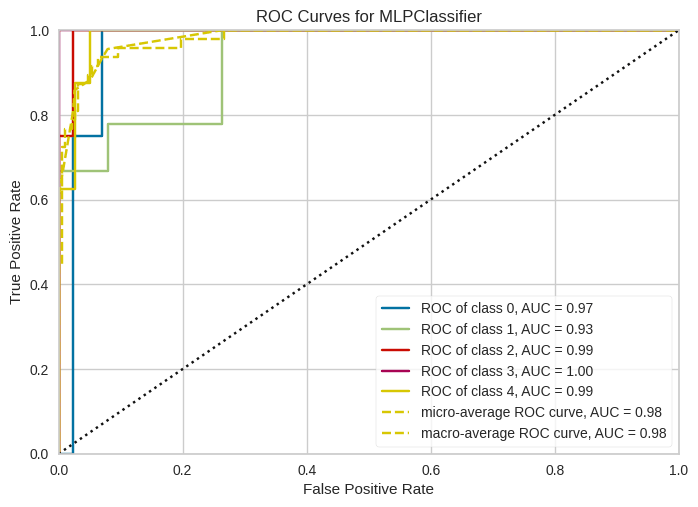

<Axes: title={'center': 'ROC Curves for MLPClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(mlp)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_mlp = mlp.predict_proba(X_test)
unique_classes = np.unique(y)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_mlp[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.9651
Класс '1': AUC = 0.9327
Класс '2': AUC = 0.9942
Класс '3': AUC = 1.0000
Класс '4': AUC = 0.9872


$\large\text{График показывает, что модель отлично справляется с предсказанием принадлежности к классам, показатели очень высокие.}$

$\large\text{Строим кривые Precision-Recall:}$

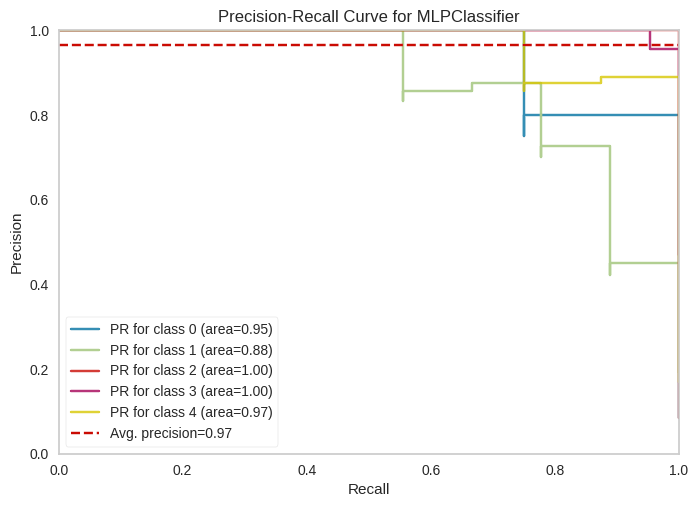

<Axes: title={'center': 'Precision-Recall Curve for MLPClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    mlp,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель немнорго хуже предсказывает 1 класс, чем остальные.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_mlp[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.5353
Класс 1: оптимальный порог = 0.0000
Класс 2: оптимальный порог = 0.0112
Класс 3: оптимальный порог = 0.8344
Класс 4: оптимальный порог = 0.0008


$\large\text{Строим график обучения модели:}$

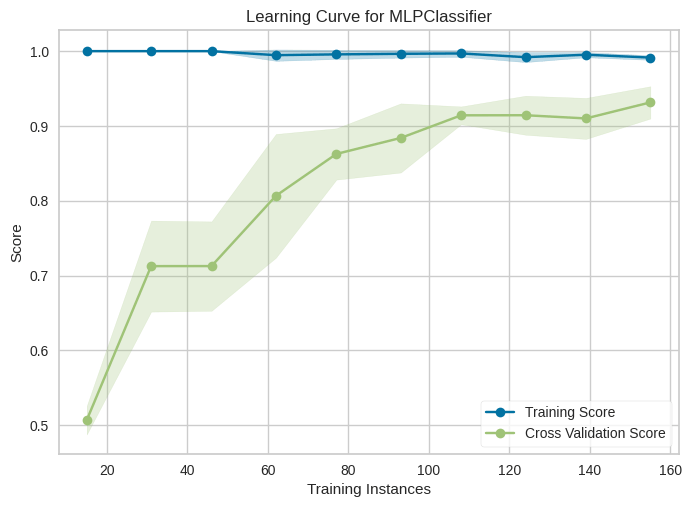

<Axes: title={'center': 'Learning Curve for MLPClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    MLPC_pipeline,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X, y)
visualizer.show()

$\large\text{График демонстрирует переобучение модели, так как на train'е показатели практически всегда равны 1.}$

### $\textbf{RandomForestСlassifier}$

In [ ]:
from sklearn.ensemble import RandomForestClassifier

$\large\text{Создаем pipeline для RandomForestClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
RFC_pipeline = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, max_depth=7, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_forest = cross_validate(
    estimator=RFC_pipeline,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_forest.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9399
train_accuracy: 1.0000
test_f1_weighted: 0.9386
train_f1_weighted: 1.0000
test_precision_weighted: 0.9421
train_precision_weighted: 1.0000
test_recall_weighted: 0.9399
train_recall_weighted: 1.0000


$\large\text{По результатам кросс-валидации похоже на переобучение, так как на train'е все метрики равна 1.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

forest = RFC_pipeline.fit(X_train, y_train)

finish = time.time()
forest_time = finish - start
print(f'Education time: {forest_time:.6f}')

Education time: 0.185051


$\large\text{Выводим accuracy модели:}$

In [ ]:
forest_score = forest.score(X_test, y_test)
print(f'{forest_score:.4f}')

0.9149


$\large\text{Accuracy равна 0,92, это показатель очень хорошей модели.}$

$\large\text{Выводим матрицу ошибок:}$

<Axes: >

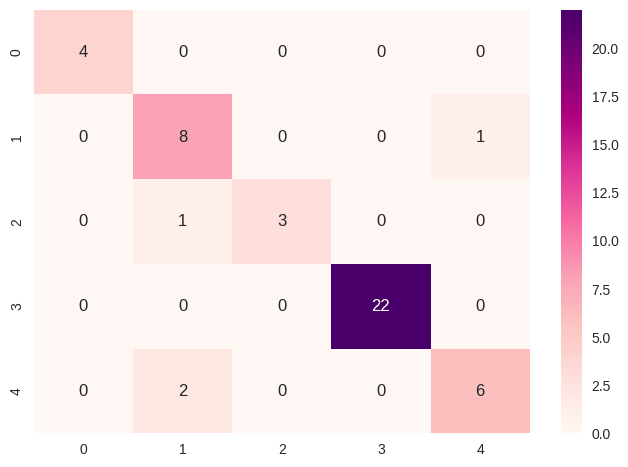

In [ ]:
y_test_pred_forest = forest.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_forest), cmap='RdPu', annot=True)

$\large\text{Матрица ошибок показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - нет ошибок,}$ <br>
$\large\text{1 класс - 1 ошибка,}$ <br>
$\large\text{2 класс - 1 ошибка,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 2 ошибки}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_forest))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       0.73      0.89      0.80         9
           2       1.00      0.75      0.86         4
           3       1.00      1.00      1.00        22
           4       0.86      0.75      0.80         8

    accuracy                           0.91        47
   macro avg       0.92      0.88      0.89        47
weighted avg       0.92      0.91      0.92        47



$\large\text{Отчет показывает, что модель достаточно хорошо справляется с предсказанием для каждого класса.}$

$\large\text{Строим кривые ROC-AUC:}$

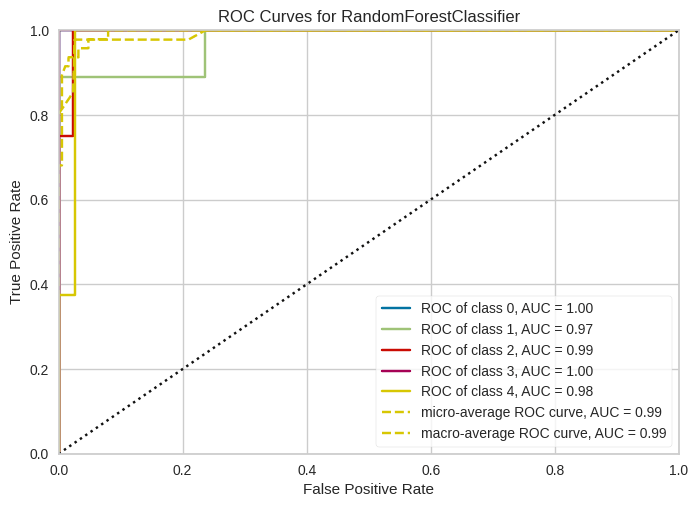

<Axes: title={'center': 'ROC Curves for RandomForestClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(forest)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_forest = forest.predict_proba(X_test)
unique_classes = np.unique(y)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_forest[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 1.0000
Класс '1': AUC = 0.9737
Класс '2': AUC = 0.9942
Класс '3': AUC = 1.0000
Класс '4': AUC = 0.9840


$\large\text{График показывает, что модель хорошо справилась с предсказанием.}$

$\large\text{Строим кривые Precision-Recall:}$

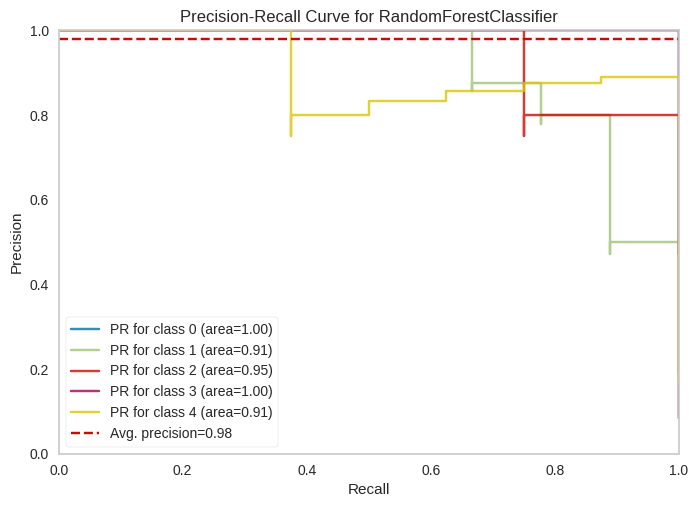

<Axes: title={'center': 'Precision-Recall Curve for RandomForestClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    forest,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель отлично справилась с предсказанием.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_forest[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.5905
Класс 1: оптимальный порог = 0.6004
Класс 2: оптимальный порог = 0.3141
Класс 3: оптимальный порог = 0.5600
Класс 4: оптимальный порог = 0.3800


$\large\text{Строим график обучения модели:}$

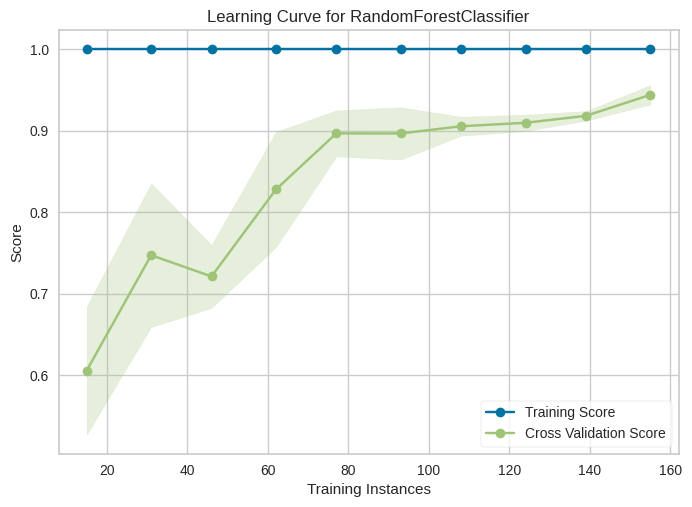

<Axes: title={'center': 'Learning Curve for RandomForestClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    RFC_pipeline,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X, y)
visualizer.show()

$\large\text{Наблюдаем переобучение, так как на train'е показатели всегда равны 1 и имеется разрыв с CV score.}$

### $\textbf{SVC}$

In [ ]:
from sklearn.svm import SVC

$\large\text{Создаем pipeline для SVMClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
SVC_pipeline = make_pipeline(StandardScaler(), SVC(C=7, max_iter=10000, kernel='rbf', probability=True, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_svc = cross_validate(
    estimator=SVC_pipeline,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_svc.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9228
train_accuracy: 0.9636
test_f1_weighted: 0.9174
train_f1_weighted: 0.9634
test_precision_weighted: 0.9264
train_precision_weighted: 0.9685
test_recall_weighted: 0.9228
train_recall_weighted: 0.9636


$\large\text{По результатам кросс-валидации модель работает отлично, пере- и недообучение отсуствует.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

svc = SVC_pipeline.fit(X_train, y_train)

finish = time.time()
svc_time = finish - start
print(f'Education time: {svc_time:.6f}')

Education time: 0.023063


$\large\text{Выводим accuracy модели:}$

In [ ]:
svc_score = svc.score(X_test, y_test)
print(f'{svc_score:.4f}')

0.8936


$\large\text{Accuracy равен 89,4, модель работает достаточно хорошо.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

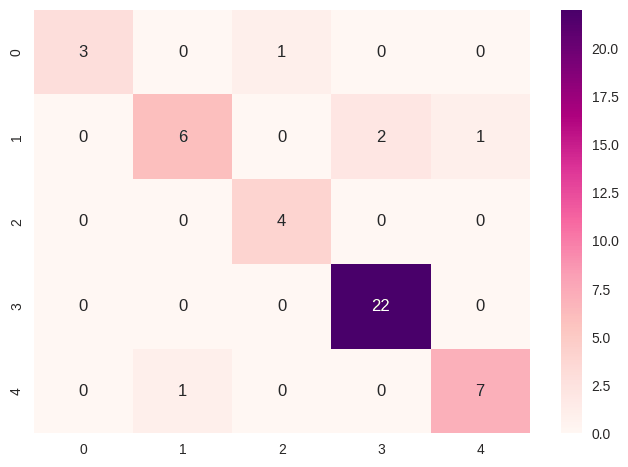

In [ ]:
y_test_pred_svc = svc.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_svc), cmap='RdPu', annot=True)

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 1 ошибка,}$ <br>
$\large\text{1 класс - 3 ошибки,}$ <br>
$\large\text{2 класс - нет ошибок,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 1 ошибка}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_svc))

              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.86      0.67      0.75         9
           2       0.80      1.00      0.89         4
           3       0.92      1.00      0.96        22
           4       0.88      0.88      0.88         8

    accuracy                           0.89        47
   macro avg       0.89      0.86      0.87        47
weighted avg       0.90      0.89      0.89        47



$\large\text{Отчет показывает, что модель достаточно хорошо предсказывает классы, но хуже справляется с 1 классом.}$

$\large\text{Строим кривые ROC-AUC:}$

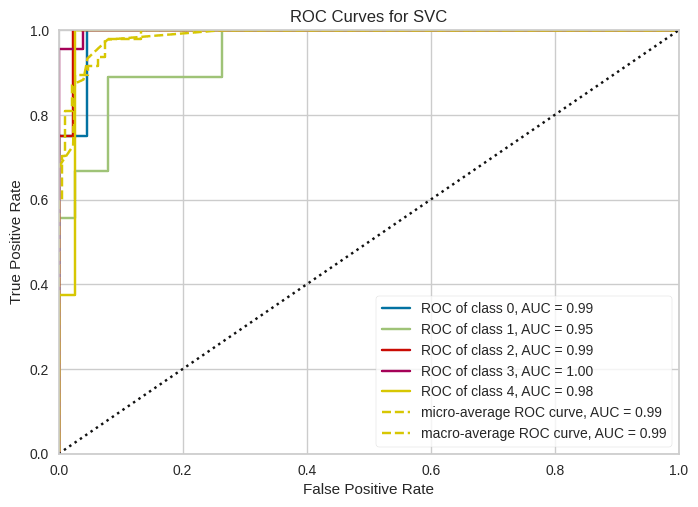

<Axes: title={'center': 'ROC Curves for SVC'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(svc)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_svc = svc.predict_proba(X_test)
unique_classes = np.unique(y)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_svc[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.9884
Класс '1': AUC = 0.9503
Класс '2': AUC = 0.9942
Класс '3': AUC = 0.9982
Класс '4': AUC = 0.9840


$\large\text{График показывает, что модель отлично справляется с предсказанием принадлежности к классам.}$

$\large\text{Строим кривые Precision-Recall:}$

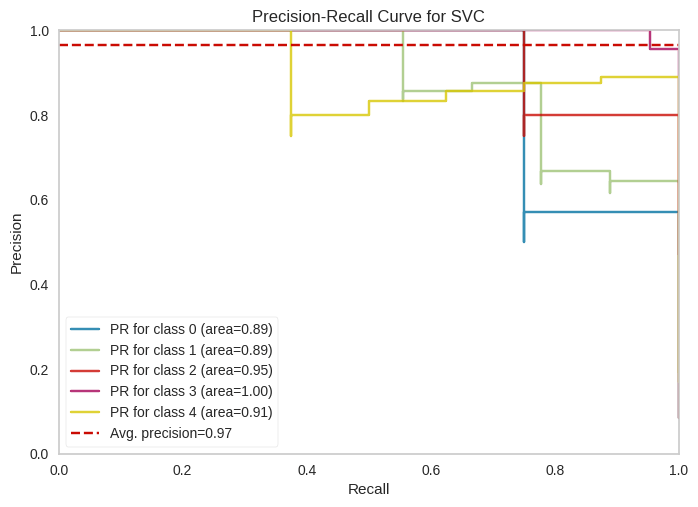

<Axes: title={'center': 'Precision-Recall Curve for SVC'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    svc,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель достаточно хорошо справилась с предсказанием.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_svc[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.3364
Класс 1: оптимальный порог = 0.1785
Класс 2: оптимальный порог = 0.5049
Класс 3: оптимальный порог = 0.6188
Класс 4: оптимальный порог = 0.2255


$\large\text{Строим график обучения модели:}$

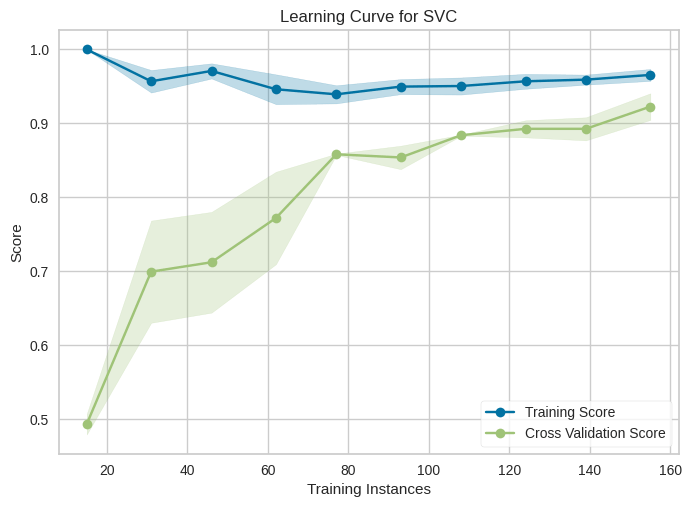

<Axes: title={'center': 'Learning Curve for SVC'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    SVC_pipeline,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X, y)
visualizer.show()

$\large\text{График обучения показывает, что модель умеренно переобучена, так как имеется большой разрыв между training score и CV score на малых значениях выборки.}$

### $\textbf{GaussianNB}$

In [ ]:
from sklearn.naive_bayes import GaussianNB

$\large\text{Создаем pipeline для GaussianNB: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
GNB_pipeline = make_pipeline(StandardScaler(), GaussianNB())

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_gnb = cross_validate(
    estimator=GNB_pipeline,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_gnb.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.7637
train_accuracy: 0.7920
test_f1_weighted: 0.7912
train_f1_weighted: 0.8159
test_precision_weighted: 0.9091
train_precision_weighted: 0.9047
test_recall_weighted: 0.7637
train_recall_weighted: 0.7920


$\large\text{По результатам кросс-вадидации модель не очень хорошо справилась с предсказанием, accuracy test'а и trein'а достаточно близки друг к другу и оба не очень большие}$
$\large\text{значения, это похоже на недообучение.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

gnb = GNB_pipeline.fit(X_train, y_train)

finish = time.time()
gnb_time = finish - start
print(f'Education time: {gnb_time:.6f}')

Education time: 0.007343


$\large\text{Выводим accuracy модели:}$

In [ ]:
gnb_score = gnb.score(X_test, y_test)
print(f'{gnb_score:.4f}')

0.8511


$\large\text{Accuracy равна 0,85, это показатель достаточно хорошей модели.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

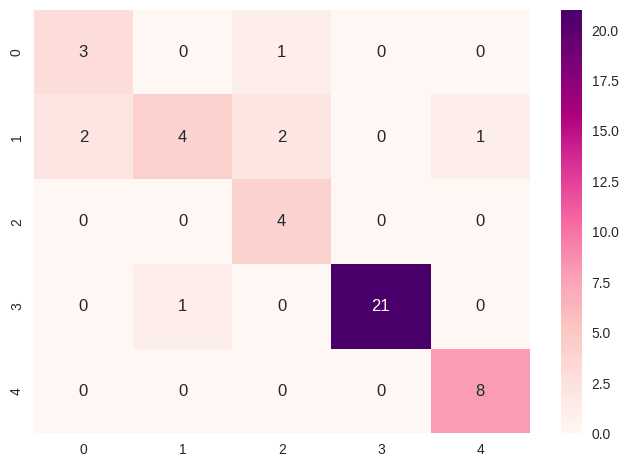

In [ ]:
y_test_pred_gnb = gnb.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_gnb), cmap='RdPu', annot=True)

$\large\text{Матрица ошибок показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс- 1 ошибка,}$ <br>
$\large\text{1 класс - 5 ошибок,}$ <br>
$\large\text{2 класс - нет ошибок,}$ <br>
$\large\text{3 класс - 1 ошибка,}$ <br>
$\large\text{4 класс- нет ошибок}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_gnb))

              precision    recall  f1-score   support

           0       0.60      0.75      0.67         4
           1       0.80      0.44      0.57         9
           2       0.57      1.00      0.73         4
           3       1.00      0.95      0.98        22
           4       0.89      1.00      0.94         8

    accuracy                           0.85        47
   macro avg       0.77      0.83      0.78        47
weighted avg       0.87      0.85      0.85        47



$\large\text{Отчет показывает, что модель с некоторыми классами (классы 0, 1, 2) справилась хуже, чем с остальными.}$

$\large\text{Строим кривые ROC-AUC:}$

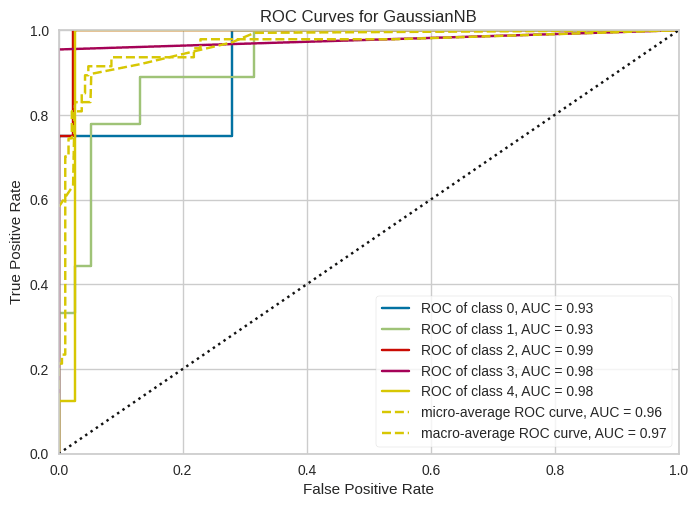

<Axes: title={'center': 'ROC Curves for GaussianNB'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(gnb)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_gnb = gnb.predict_proba(X_test)
unique_classes = np.unique(y)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_gnb[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.9302
Класс '1': AUC = 0.9298
Класс '2': AUC = 0.9942
Класс '3': AUC = 0.9773
Класс '4': AUC = 0.9776


$\large\text{График показывает, что модель практически идеально справилась с предсказанием.}$

$\large\text{Строим кривые Precision-Recall:}$

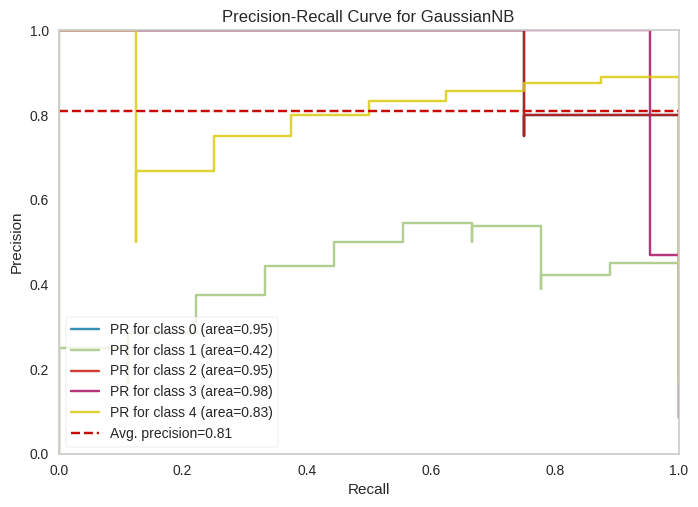

<Axes: title={'center': 'Precision-Recall Curve for GaussianNB'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    gnb,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{По графику видно, что модель очень плохо справилась с предсказанием 2 класса.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_gnb[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.8486
Класс 1: оптимальный порог = 0.0574
Класс 2: оптимальный порог = 1.0000
Класс 3: оптимальный порог = 0.8897
Класс 4: оптимальный порог = 0.6667


$\large\text{Строим график обучения модели:}$

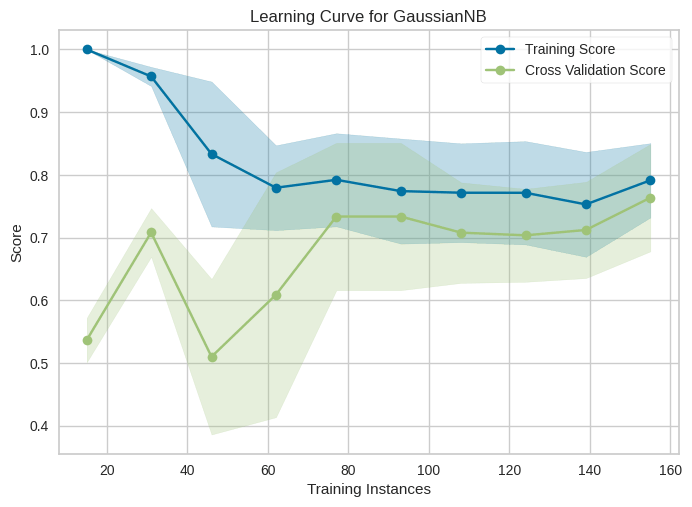

<Axes: title={'center': 'Learning Curve for GaussianNB'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    GNB_pipeline,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X, y)
visualizer.show()

$\large\text{График демонстрирует явное недообучение.}$

### $\textbf{GradientBoostingClassifier}$

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

$\large\text{Создаем pipeline для GradientBoostingClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
GBC_pipeline = make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, max_features=0.7, subsample=0.8, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_gbc = cross_validate(
    estimator=GBC_pipeline,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_gbc.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9271
train_accuracy: 1.0000
test_f1_weighted: 0.9248
train_f1_weighted: 1.0000
test_precision_weighted: 0.9365
train_precision_weighted: 1.0000
test_recall_weighted: 0.9271
train_recall_weighted: 1.0000


$\large\text{По результатам кросс-валидации возникает предположение о переобучении, так как accuracy на train'е равно 1.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

gbc = GBC_pipeline.fit(X_train, y_train)

finish = time.time()
gbc_time = finish - start
print(f'Education time: {gbc_time:.6f}')

Education time: 3.849373


$\large\text{Выводим accuracy модели:}$

In [ ]:
gbc_score = gbc.score(X_test, y_test)
print(f'{gbc_score:.4f}')

0.9149


$\large\text{Accuracy равна 0,92, это показатель отличной модели.}$

$\large\text{Выводим матрицу ошибок:}$

<Axes: >

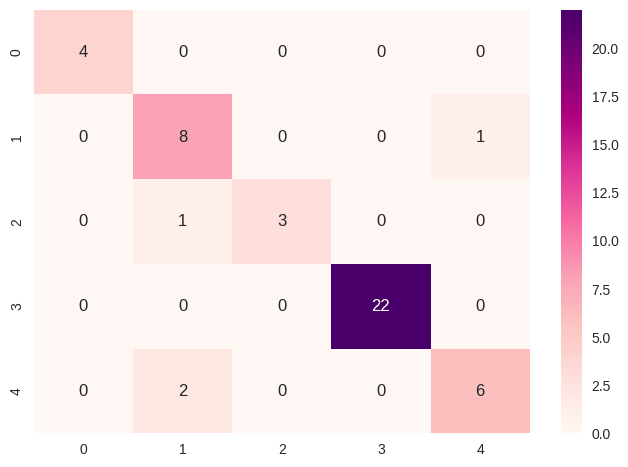

In [ ]:
y_test_pred_gbc = gbc.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_gbc), cmap='RdPu', annot=True)

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - нет ошибок,}$ <br>
$\large\text{1 класс - 1 ошибка,}$ <br>
$\large\text{2 класс - 1 ошибка,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 2 ошибки}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_gbc))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       0.73      0.89      0.80         9
           2       1.00      0.75      0.86         4
           3       1.00      1.00      1.00        22
           4       0.86      0.75      0.80         8

    accuracy                           0.91        47
   macro avg       0.92      0.88      0.89        47
weighted avg       0.92      0.91      0.92        47



$\large\text{Отчет показывает, что модель достаточно хорошо справляется с предсказанием принадлежности к классам.}$

$\large\text{Строим кривые ROC-AUC:}$

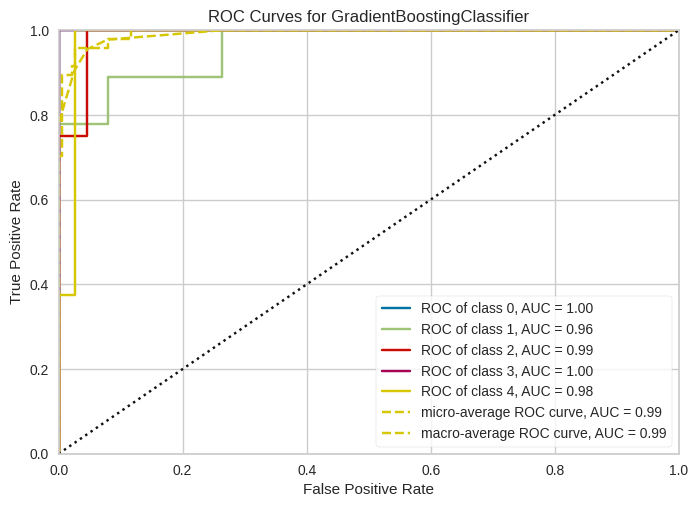

<Axes: title={'center': 'ROC Curves for GradientBoostingClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(gbc)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_gbc = gbc.predict_proba(X_test)
unique_classes = np.unique(y)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_gbc[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 1.0000
Класс '1': AUC = 0.9620
Класс '2': AUC = 0.9884
Класс '3': AUC = 1.0000
Класс '4': AUC = 0.9840


$\large\text{График показывает, что модель работает практически идеально.}$

$\large\text{Строим кривые Precision-Recall:}$

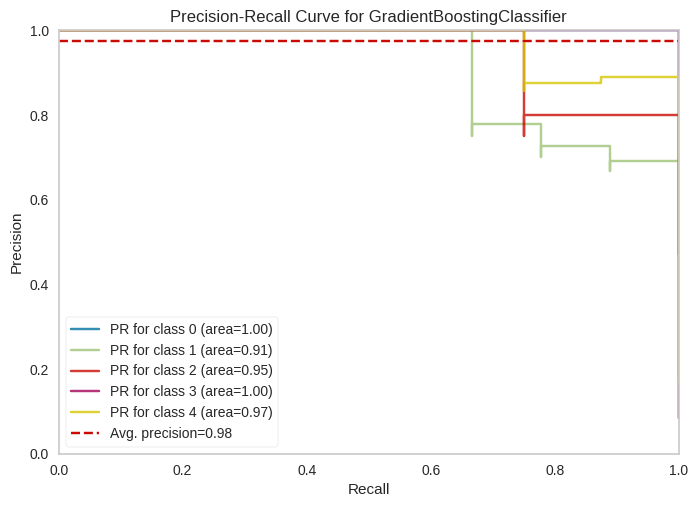

<Axes: title={'center': 'Precision-Recall Curve for GradientBoostingClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    gbc,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель справляется отлично.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_gbc[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.9986
Класс 1: оптимальный порог = 0.6569
Класс 2: оптимальный порог = 0.0000
Класс 3: оптимальный порог = 1.0000
Класс 4: оптимальный порог = 0.0136


$\large\text{Строим график обучения модели:}$

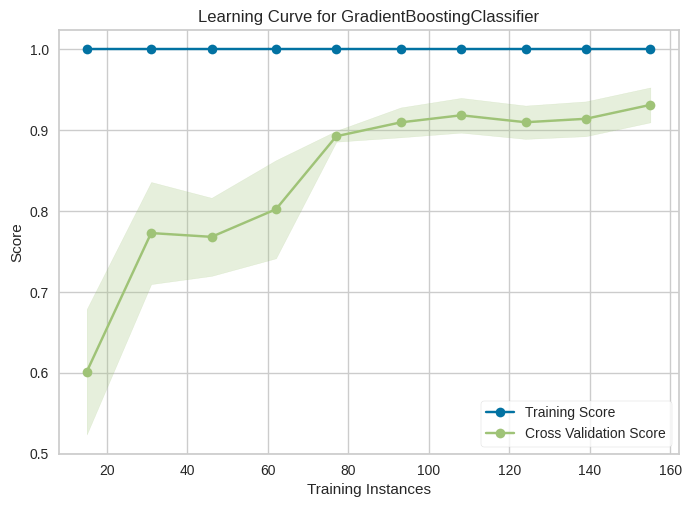

<Axes: title={'center': 'Learning Curve for GradientBoostingClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    GBC_pipeline,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X, y)
visualizer.show()

$\large\text{График показывает, что модель переобучилась, так как accuracy на  train'е всегда равна 1.}$

### $\large\textbf{Выводы}$

$\large\text{Строим сводную таблицу по всем моделям и выбираем самую перспективную:}$

In [ ]:
results = {
    'Logistic Regression': {
        'Accuracy': cv_results_LR['test_accuracy'].mean(),
        'F1 Weighted': cv_results_LR['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_LR['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_LR['test_recall_weighted'].mean(),
        'Train Time (s)': LR_time,
        'Overfitting Gap (Acc)': LR_score - cv_results_LR['test_accuracy'].mean()
    },
    'Decision Tree Classifier': {
        'Accuracy': cv_results_tree['test_accuracy'].mean(),
        'F1 Weighted': cv_results_tree['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_tree['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_tree['test_recall_weighted'].mean(),
        'Train Time (s)': tree_time,
        'Overfitting Gap (Acc)': tree_score - cv_results_tree['test_accuracy'].mean()
    },
    'KNN Classifier': {
        'Accuracy': cv_results_knc['test_accuracy'].mean(),
        'F1 Weighted': cv_results_knc['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_knc['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_knc['test_recall_weighted'].mean(),
        'Train Time (s)': knc_time,
        'Overfitting Gap (Acc)': knc_score - cv_results_knc['test_accuracy'].mean()
    },
    'MLP Classifier': {
        'Accuracy': cv_results_mlp['test_accuracy'].mean(),
        'F1 Weighted': cv_results_mlp['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_mlp['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_mlp['test_recall_weighted'].mean(),
        'Train Time (s)': mlp_time,
        'Overfitting Gap (Acc)': mlp_score - cv_results_mlp['test_accuracy'].mean()
    },
    'Random Forest Classifier': {
        'Accuracy': cv_results_forest['test_accuracy'].mean(),
        'F1 Weighted': cv_results_forest['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_forest['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_forest['test_recall_weighted'].mean(),
        'Train Time (s)': forest_time,
        'Overfitting Gap (Acc)': forest_score - cv_results_forest['test_accuracy'].mean()
    },

    'SVC (RBF)': {
        'Accuracy': cv_results_svc['test_accuracy'].mean(),
        'F1 Weighted': cv_results_svc['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_svc['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_svc['test_recall_weighted'].mean(),
        'Train Time (s)': svc_time,
        'Overfitting Gap (Acc)': svc_score - cv_results_svc['test_accuracy'].mean()
    },
    'GaussianNB': {
        'Accuracy': cv_results_gnb['test_accuracy'].mean(),
        'F1 Weighted': cv_results_gnb['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_gnb['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_gnb['test_recall_weighted'].mean(),
        'Train Time (s)': gnb_time,
        'Overfitting Gap (Acc)': gnb_score - cv_results_gnb['test_accuracy'].mean()
    },
    'GradientBoostingClassifier': {
        'Accuracy': cv_results_gbc['test_accuracy'].mean(),
        'F1 Weighted': cv_results_gbc['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_gbc['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_gbc['test_recall_weighted'].mean(),
        'Train Time (s)': gbc_time,
        'Overfitting Gap (Acc)': gbc_score - cv_results_gbc['test_accuracy'].mean()
    }
}


df_results = pd.DataFrame(results).T

positive_values = df_results[df_results['Overfitting Gap (Acc)'] > 0]['Overfitting Gap (Acc)']
min_positive = positive_values.min()
max_positive = positive_values.max()

df_results = df_results.round(4)

styled_df = df_results.style.background_gradient(cmap='Blues', subset=['Accuracy', 'F1 Weighted', 'Precision Weighted', 'Recall Weighted']) \
                            .background_gradient(cmap='Greens_r', subset=['Overfitting Gap (Acc)'],  vmin=min_positive, vmax=max_positive) \
                            .background_gradient(cmap='Reds', subset=['Train Time (s)']) \
                            .format(precision=4) \
                            .set_caption("Сводная таблица метрик моделей") \
                            .set_table_styles([{
                                'selector': 'caption',
                                'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'center')]
                            }])

styled_df = styled_df.applymap(
    lambda x: 'background-color: #d3d3d3' if isinstance(x, (int, float)) and x < 0 else '',
    subset=['Overfitting Gap (Acc)']
)

display(styled_df)

,Accuracy,F1 Weighted,Precision Weighted,Recall Weighted,Train Time (s),Overfitting Gap (Acc)
Logistic Regression,0.8885,0.8701,0.8677,0.8885,0.0170,-0.0162
Decision Tree Classifier,0.8969,0.8946,0.9052,0.8969,0.0075,-0.0458
KNN Classifier,0.8799,0.8726,0.8786,0.8799,0.0059,-0.0501
MLP Classifier,0.9315,0.9310,0.9415,0.9315,1.5990,-0.0591
Random Forest Classifier,0.9399,0.9386,0.9421,0.9399,0.1851,-0.0251
SVC (RBF),0.9228,0.9174,0.9264,0.9228,0.0231,-0.0292
GaussianNB,0.7637,0.7912,0.9091,0.7637,0.0073,0.0874
GradientBoostingClassifier,0.9271,0.9248,0.9365,0.9271,3.8494,-0.0122


$\large\text{Серый цвет в колонке Overfitting Gap означает, что точность на валидации оказалась выше, чем на обучении. Это не всегда значит, что модель недо- или переобучена,}$
$\large\text{просто требуется проверка данных или разбиения выборки.}$
$\large\text{В нашем случае как раз возможен второй вариант, так как данных изначально было очень мало и при разбиении на выборки мог произойти сильный дисбаланс данных.}$

$\large\text{Сравнивая метрики всех моделей, самой лучшей оказалась RandomForestClassifier с параметрами:}$ <br>
$\large\text{Accuracy = 0,9399,}$ <br>
$\large\text{F1 Weighted = 0,9389,}$ <br>
$\large\text{Precision Weighted = 0,9421,}$ <br>
$\large\text{Recall Weighted = 0,9399}$ <br>

$\large\text{Выбираем данную модель для настройки гиперпараметров для ее улучшения.}$

### $\large\textbf{Настройка гиперпараметров перспективной модели}$

$\large\text{Разбиваем данные на обучающую, тестовую и валидационную выборки:}$

In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

$\large\text{Для подбора гиперпараметров будем использовать Bayesian Optimization. В отличие от GridSearch и RandomizedSearch этот метод учитывает}$ $\large\text{предыдущие ошибки и ищет новые новые комбинации, следовательно, точность подбора повышается.}$

In [ ]:
!pip install optuna
import optuna

$\large\text{Создаем целевую функцию - то, что optuna будет оптимизировать. Аргумент 'trial' - объект, который предлагает значения гиперпараметров на каждой итерации.}$

$\large\text{Пояснения по функции:}$ <br>
$\large\text{trial.suggest_int - предлагает целые численные значения,}$ <br>
$\large\text{trial.suggest_categorical - количество признаков для поиска лучшего разделения}$ <br>
$\large\text{В конце возвращаем среднее значение accuracy по кросс-валидации.}$

In [ ]:
def objective_rf(trial):
    pipeline = make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=trial.suggest_int('n_estimators', 100, 500, step=10),
            max_depth=trial.suggest_int('max_depth', 5, 30, step=2),
            min_samples_split=trial.suggest_int('min_samples_split', 2, 20),
            min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 10),
            max_features=trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
            bootstrap=trial.suggest_categorical('bootstrap', [True, False]),
            class_weight=trial.suggest_categorical('class_weight', ['balanced', None]),
            random_state=42,
            n_jobs=-1
        )
    )

    return cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='accuracy').mean()

$\large\text{Создаем объект исследования study:}$ <br>
$\large\text{optuna.samplers.TPESampler - алгоритм байесовской оптимизации (Tree-structured Parzen Estimator - эффективный алгоритм байесовской оптимизации,}$
$\large\text{он моделирует распределение "хороших" и "плохих" гиперпараметров).}$ <br>
$\large\text{Запускаем оптимизацию:}$

In [ ]:
study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_rf.optimize(objective_rf, n_trials=100, show_progress_bar=True)

[I 2026-05-12 16:11:47,917] A new study created in memory with name: no-name-f4d27192-b527-482a-b601-2f40422e15e8


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-05-12 16:11:51,591] Trial 0 finished with value: 0.8993216157878509 and parameters: {'n_estimators': 250, 'max_depth': 29, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'bootstrap': True, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8993216157878509.
[I 2026-05-12 16:12:01,667] Trial 1 finished with value: 0.9135060129509713 and parameters: {'n_estimators': 490, 'max_depth': 25, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': None, 'bootstrap': True, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.9135060129509713.
[I 2026-05-12 16:12:06,235] Trial 2 finished with value: 0.8270120259019427 and parameters: {'n_estimators': 210, 'max_depth': 13, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': None, 'bootstrap': False, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.9135060129509713.
[I 2026-05-12 16:12:13,952] Trial 3 finished with value: 0.8775824853530682 and parameters: {'n_estimators'

$\large\text{Выводим лучшее значение по кросс-валидации и параметры лучшей комбинации:}$

In [ ]:
print(f"Best CV: {study_rf.best_value:.4f}")
print(f"Best params: {study_rf.best_params}")

Best CV: 0.9423
Best params: {'n_estimators': 270, 'max_depth': 11, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'bootstrap': True, 'class_weight': 'balanced'}


$\large\text{Создаем модель с наилучшими параметрами, обучаем ее и предсказываем значения на валидационной выборке:}$

In [ ]:
best_rf = RandomForestClassifier(
    n_estimators = study_rf.best_params['n_estimators'],
    max_depth = study_rf.best_params['max_depth'],
    min_samples_split = study_rf.best_params['min_samples_split'],
    min_samples_leaf = study_rf.best_params['min_samples_leaf'],
    max_features = study_rf.best_params['max_features'],
    bootstrap = study_rf.best_params['bootstrap'],
    class_weight = study_rf.best_params.get('class_weight', None),
    random_state=42,
    n_jobs=-1
)

best_pipeline_rf = make_pipeline(StandardScaler(), best_rf)
best_pipeline_rf.fit(X_train, y_train)

y_pred_train_rf = best_pipeline_rf.predict(X_train)
y_pred_val_rf = best_pipeline_rf.predict(X_val)

train_acc_rf = accuracy_score(y_train, y_pred_train_rf)
val_acc_rf = accuracy_score(y_val, y_pred_val_rf)

print(f"Train Accuracy: {train_acc_rf:.4f}")
print(f"Validation Accuracy: {val_acc_rf:.4f}")
print(f"Gap: {train_acc_rf - val_acc_rf:.4f}")
print(f"F1-weighted: {f1_score(y_val, y_pred_val_rf, average='weighted'):.4f}")
print(f"Precision-weighted: {precision_score(y_val, y_pred_val_rf, average='weighted'):.4f}")
print(f"Recall-weighted: {recall_score(y_val, y_pred_val_rf, average='weighted'):.4f}")

Train Accuracy: 0.9784
Validation Accuracy: 0.9149
Gap: 0.0635
F1-weighted: 0.9028
Precision-weighted: 0.9014
Recall-weighted: 0.9149


$\large\text{Разрыв между Train Accuracy и Validation Accuracy совсем небольшой, всего 0,06, следовательно, пере- и недообучение отсуствует.}$
$\large\text{Остальные метрики так же имеют высокие показатели.}$

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_val, y_pred_val_rf, digits=4))

              precision    recall  f1-score   support

           0     0.5000    0.2500    0.3333         4
           1     0.8182    1.0000    0.9000         9
           2     0.6667    0.6667    0.6667         3
           3     1.0000    1.0000    1.0000        23
           4     1.0000    1.0000    1.0000         8

    accuracy                         0.9149        47
   macro avg     0.7970    0.7833    0.7800        47
weighted avg     0.9014    0.9149    0.9028        47



$\large\text{Некоторые классы (0 и 2) модель предсказа очень плохо. В нашем случае это связано с малым объемом данных, так как в изначальном датасете всего 240 строк}$
$\large\text{и сильный дисбаланс классов.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

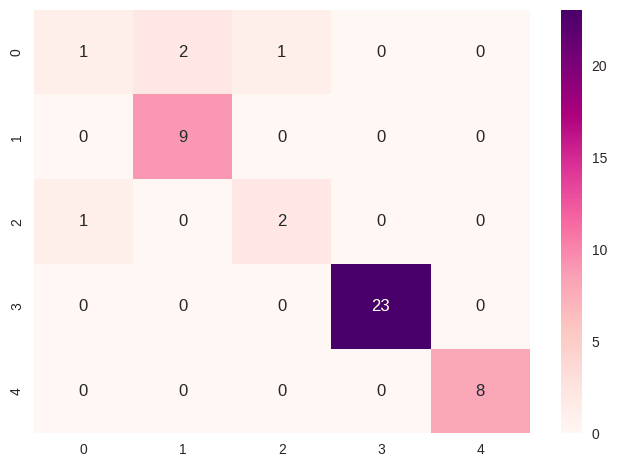

In [ ]:
sns.heatmap(confusion_matrix(y_val, y_pred_val_rf), cmap='RdPu', annot=True)

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 3 ошибки,}$ <br>
$\large\text{1 класс - нет ошибок,}$ <br>
$\large\text{2 класс - 1 ошибка,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - нет ошибок}$ <br>

$\large\text{Строим график обучения модели:}$

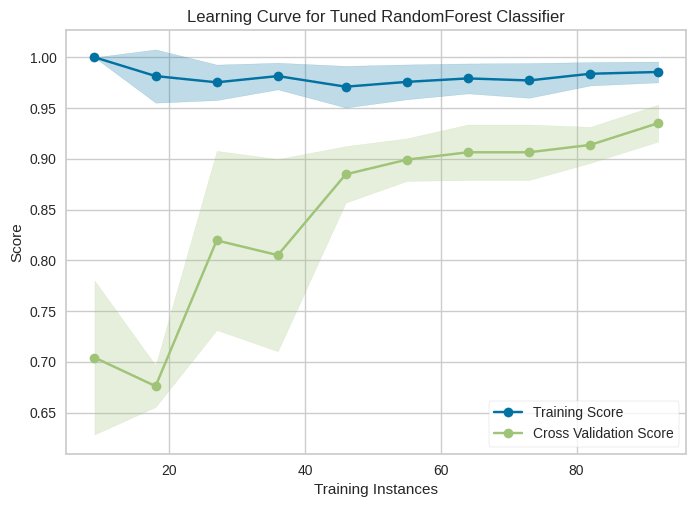

<Axes: title={'center': 'Learning Curve for Tuned RandomForest Classifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    best_rf,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1,
    title='Learning Curve for Tuned RandomForest Classifier',
    xlabel='Training Instances',
    ylabel='Accuracy'
)

visualizer.fit(X_train, y_train)
visualizer.show()

$\large\text{График демонстрирует небольшое переобучение модели, так как на малых значениях выборки имеется большой разрыв между Training Score и CV Score.}$

$\large\text{Таким образом, после подбора гиперпараметров точность модели равна 0,92. Это меньше, чем у изначальной модели (0,9399), но, учитывая малое количество}$ $\large\text{данных на каждой выборке, это очень хороший результат.}$

## $\Large\textbf{Обучение моделей на данных с аугментацией}$

$\large\text{Аугментация - это способ искусственно увеличить объем и разнообразие обучающей выборки путем создания модифицированных версий существующих данных.}$

$\large\text{Для аугментации данных используем SMOTE. Его идея заключается в том, что для создания нового примера редкого класса он находит несколько его ближайших}$
$\large\text{"соседей" и генерирует точку где-то между ними. Это позволяет "заполнить" пространство признаков новыми, правдоподобными примерами, помогая модели}$
$\large\text{лучше изучить границы между классами.}$

In [ ]:
from imblearn.over_sampling import SMOTE

$\large\text{Аугментируем данные, устанавливая, что в каждом классе будет по 1000 объектов:}$

In [ ]:
unique_classes = np.unique(y)
strategy = {cls: 1000 for cls in unique_classes}

smote = SMOTE(sampling_strategy=strategy, random_state=42)
X_aug, y_aug = smote.fit_resample(X, y)

$\large\text{Теперь в каждом классе содержится по 1000 объектов:}$

In [ ]:
pd.Series(y_aug).value_counts().sort_index()

,count
0,1000
1,1000
2,1000
3,1000
4,1000


$\large\text{Разбиваем аугментированные данные на тестовую и обучающую выборки:}$

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_aug, y_aug, test_size = 0.2, stratify=y_aug, random_state=42)

$\large\text{Для кросс-валидации так же используем StratifiedKFold:}$

In [ ]:
skf = StratifiedKFold(n_splits=7, shuffle=True, random_state=42)

### $\textbf{LogisticRegression}$

$\large\text{Создаем pipeline для Logistic Regression: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
pipe_LR = make_pipeline(StandardScaler(), LogisticRegression(solver='saga', max_iter=10000, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_LR_aug = cross_validate(
    pipe_LR,
    X=X_aug, y=y_aug,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_LR_aug.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9270
train_accuracy: 0.9280
test_f1_weighted: 0.9269
train_f1_weighted: 0.9280
test_precision_weighted: 0.9293
train_precision_weighted: 0.9300
test_recall_weighted: 0.9270
train_recall_weighted: 0.9280


$\large\text{По результатам кросс-валидации модель работает почти идеально, пере- и недообучение отсутствует.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

LR_aug = pipe_LR.fit(X_train, y_train)

finish = time.time()
LR_aug_time = finish - start
print(f'Education time: {LR_aug_time:.6f}')

Education time: 0.280077


$\large\text{Выводим accuracy модели:}$

In [ ]:
LR_aug_score = LR_aug.score(X_test, y_test)
print(f'{LR_aug_score:.4f}')

0.9330


$\large\text{Accuracy равна 0,93, это показатель практически идеальной модели.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

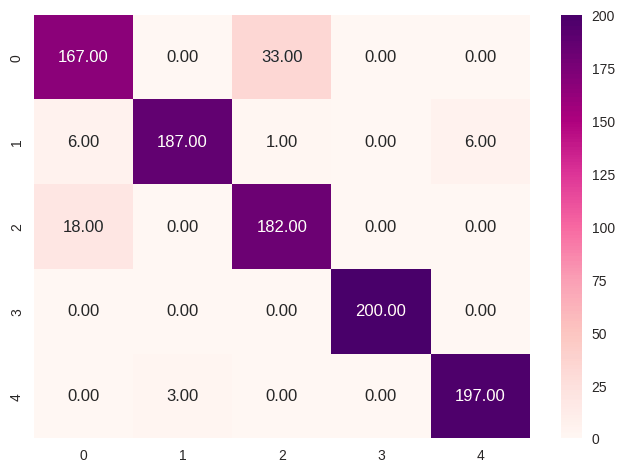

In [ ]:
y_test_pred_LR_aug = LR_aug.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_LR_aug), cmap='RdPu', annot=True, fmt='.2f')

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 33 ошибки,}$ <br>
$\large\text{1 класс - 12 ошибок,}$ <br>
$\large\text{2 класс - 18 ошибок,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 3 ошибки}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_LR_aug))

              precision    recall  f1-score   support

           0       0.87      0.83      0.85       200
           1       0.98      0.94      0.96       200
           2       0.84      0.91      0.88       200
           3       1.00      1.00      1.00       200
           4       0.97      0.98      0.98       200

    accuracy                           0.93      1000
   macro avg       0.93      0.93      0.93      1000
weighted avg       0.93      0.93      0.93      1000



$\large\text{Отчет показывает, что модель достаточно хорошо справилась с предсказанием принадлежности к классам.}$

$\large\text{Строим кривые ROC-AUC:}$

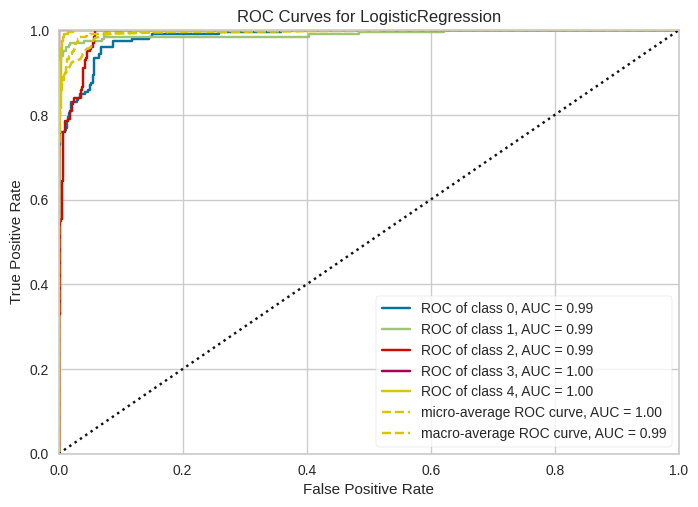

<Axes: title={'center': 'ROC Curves for LogisticRegression'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(LR_aug)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_LR_aug = LR_aug.predict_proba(X_test)
unique_classes = np.unique(y_aug)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_LR_aug[:, i])
    auc_scores[cls] = auc
    print(f"  Класс '{cls}': AUC = {auc:.4f}")

  Класс '0': AUC = 0.9853
  Класс '1': AUC = 0.9906
  Класс '2': AUC = 0.9896
  Класс '3': AUC = 1.0000
  Класс '4': AUC = 0.9993


$\large\text{График показыввет, что модель отлично работает.}$

$\large\text{Строим кривые Precision-Recall:}$

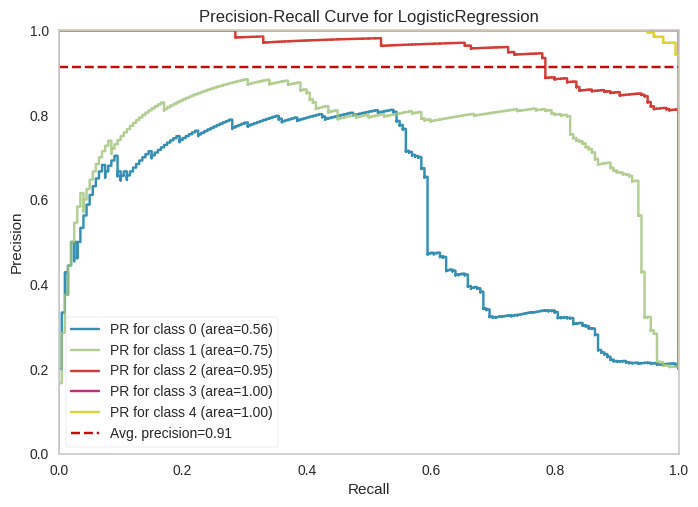

<Axes: title={'center': 'Precision-Recall Curve for LogisticRegression'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    LR_aug,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что с предсказанием принадлежности к некоторым классам (0 и 1 классы) моделей справилась гораздо хуже, чем к другим.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_LR_aug[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.2968
Класс 1: оптимальный порог = 0.2555
Класс 2: оптимальный порог = 0.2625
Класс 3: оптимальный порог = 0.8439
Класс 4: оптимальный порог = 0.2853


$\large\text{Строим график обучения модели:}$

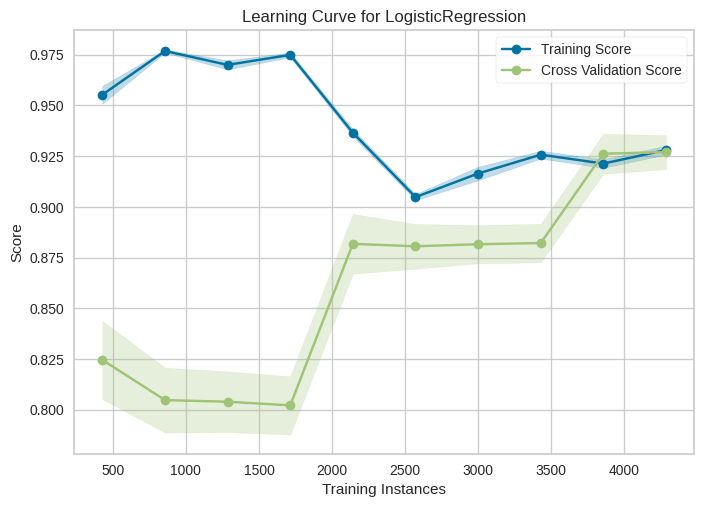

<Axes: title={'center': 'Learning Curve for LogisticRegression'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    LR_aug,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X_aug, y_aug)
visualizer.show()

$\large\text{График показывает, что модель немного переобучена, так как имеется разрыв между значениями accuracy train'а и CV на малых значениях выборки.}$

### $\textbf{DecisionTreeClassifier}$

$\large\text{Создаем pipeline для DecisionTreeClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
tree_aug = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=5, random_state=42))

$\large\text{Проводим кросс-валидацию:}$


In [ ]:
cv_results_tree_aug = cross_validate(
    tree_aug,
    X=X_aug, y=y_aug,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_tree_aug.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9504
train_accuracy: 0.9549
test_f1_weighted: 0.9504
train_f1_weighted: 0.9549
test_precision_weighted: 0.9535
train_precision_weighted: 0.9576
test_recall_weighted: 0.9504
train_recall_weighted: 0.9549


$\large\text{Результаты кросс-валидации показывают, что модель работает отлично, почти идеально.}$


$\large\text{Обучаем модель и засекаем время ее обучения:}$


In [ ]:
start = time.time()

tree_aug = tree_aug.fit(X_train, y_train)

finish = time.time()
tree_aug_time = finish - start
print(f'Education time: {tree_aug_time:.6f}')

Education time: 0.021594


$\large\text{Выводим Accuracy модели:}$


In [ ]:
tree_aug_score = tree_aug.score(X_test, y_test)
print(f'{tree_aug_score:.4f}')

0.9640


$\large\text{Accuracy равна 0,96, это показатель отличной модели.}$


$\large\text{Строим матрицу ошибок:}$


<Axes: >

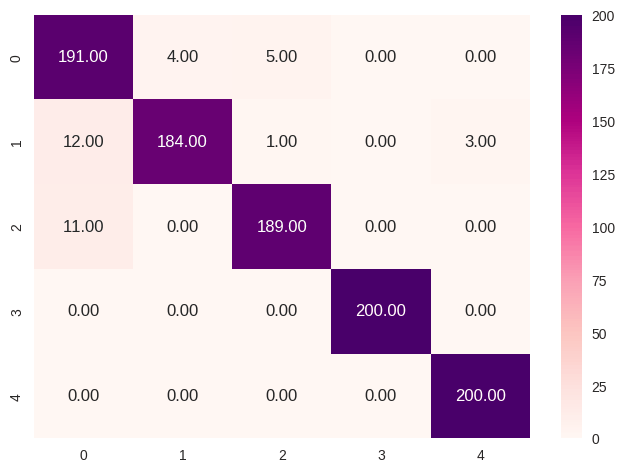

In [ ]:
y_test_pred_tree_aug = tree_aug.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_tree_aug), cmap='RdPu', annot=True, fmt='.2f')

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс- 9 ошибок,}$ <br>
$\large\text{1 класс - 13 ошибок,}$ <br>
$\large\text{2 класс - 11 ошибок,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - нет ошибок}$ <br>


$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_tree_aug))

              precision    recall  f1-score   support

           0       0.89      0.95      0.92       200
           1       0.98      0.92      0.95       200
           2       0.97      0.94      0.96       200
           3       1.00      1.00      1.00       200
           4       0.99      1.00      0.99       200

    accuracy                           0.96      1000
   macro avg       0.97      0.96      0.96      1000
weighted avg       0.97      0.96      0.96      1000



$\large\text{Отчет показывает, что модель почти идеально справляется с предсказанием принадлежности к классам.}$

$\large\text{Строим кривые ROC-AUC:}$

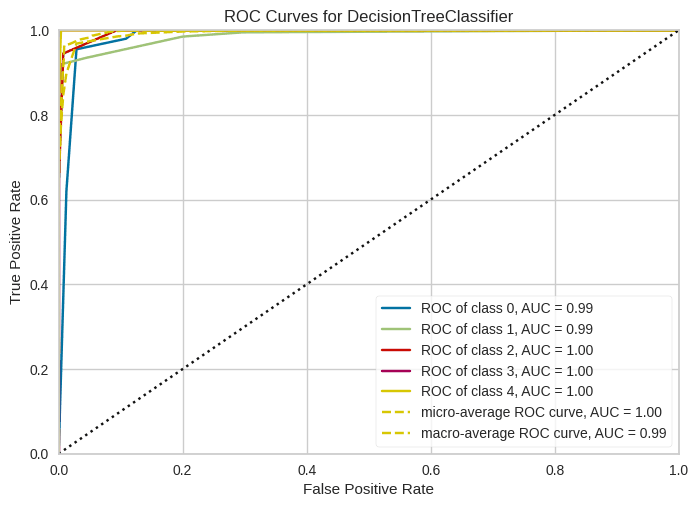

<Axes: title={'center': 'ROC Curves for DecisionTreeClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(tree_aug)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_tree_aug = tree_aug.predict_proba(X_test)
unique_classes = np.unique(y_aug)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_tree_aug[:, i])
    auc_scores[cls] = auc
    print(f"  Класс '{cls}': AUC = {auc:.4f}")

  Класс '0': AUC = 0.9851
  Класс '1': AUC = 0.9876
  Класс '2': AUC = 0.9960
  Класс '3': AUC = 1.0000
  Класс '4': AUC = 0.9997


$\large\text{График показывает, что модель работает отлично.}$

$\large\text{Строим кривые Precision-Recall:}$

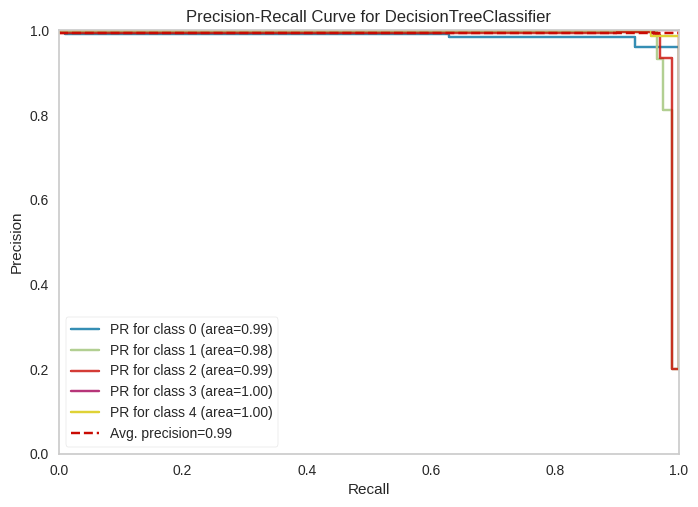

<Axes: title={'center': 'Precision-Recall Curve for DecisionTreeClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    tree_aug,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель также идеально работает.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_tree_aug[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.7889
Класс 1: оптимальный порог = 0.9100
Класс 2: оптимальный порог = 0.8911
Класс 3: оптимальный порог = 1.0000
Класс 4: оптимальный порог = 0.7453


$\large\text{Строим график обучения модели:}$

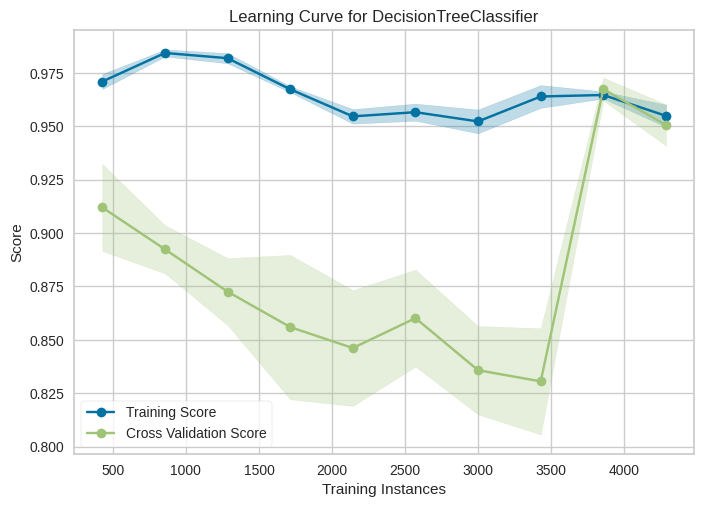

<Axes: title={'center': 'Learning Curve for DecisionTreeClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    tree_aug,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X_aug, y_aug)
visualizer.show()

$\large\text{Наблюдаем небольшое переобучение на средних значениях выборки.}$

### $\textbf{KNeighborsClassifier}$

$\large\text{Создаем pipeline для KNeighborsClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
KNC_pipeline_aug = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_knc_aug = cross_validate(
    estimator=KNC_pipeline_aug,
    X=X_aug, y=y_aug,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_knc_aug.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9898
train_accuracy: 0.9941
test_f1_weighted: 0.9898
train_f1_weighted: 0.9941
test_precision_weighted: 0.9899
train_precision_weighted: 0.9942
test_recall_weighted: 0.9898
train_recall_weighted: 0.9941


$\large\text{Результаты кросс-валидации показывают, что модель работает почти идеально, пере- и недообучение отсутствует.}$


$\large\text{Обучаем модель и засекаем время ее обучения:}$


In [ ]:
start = time.time()

knc_aug = KNC_pipeline_aug.fit(X_train, y_train)

finish = time.time()
knc_time_aug = finish - start
print(f'Education time: {knc_time_aug:.6f}')

Education time: 0.011875


$\large\text{Выводим Accuracy модели:}$

In [ ]:
knc_score_aug = knc_aug.score(X_test, y_test)
print(f'{knc_score_aug:.4f}')

0.9850


$\large\text{Accuracy равна 0,99, это показатель идеальной модели.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

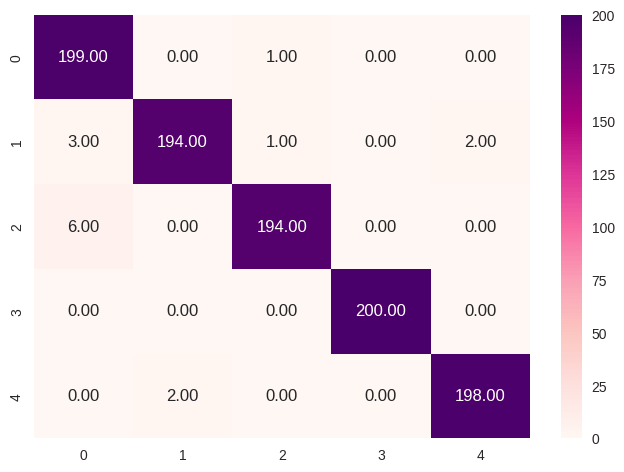

In [ ]:
y_test_pred_knc_aug = knc_aug.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_knc_aug), cmap='RdPu', annot=True, fmt='.2f')

$\large\text{Матрица ошибок показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 1 ошибка,}$ <br>
$\large\text{1 класс - 6 ошибок,}$ <br>
$\large\text{2 класс - 6 ошибок,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 2 ошибки}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_knc_aug))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98       200
           1       0.99      0.97      0.98       200
           2       0.99      0.97      0.98       200
           3       1.00      1.00      1.00       200
           4       0.99      0.99      0.99       200

    accuracy                           0.98      1000
   macro avg       0.99      0.98      0.99      1000
weighted avg       0.99      0.98      0.99      1000



$\large\text{Отчет показывает, что модель работает идеально.}$

$\large\text{Строим кривые ROC-AUC:}$

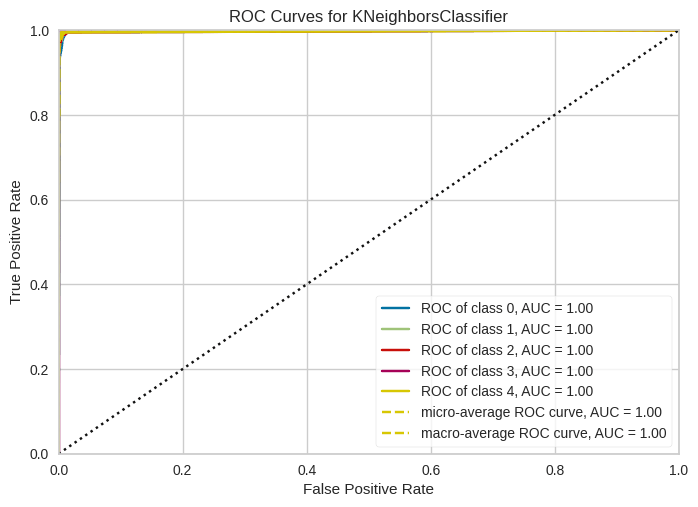

<Axes: title={'center': 'ROC Curves for KNeighborsClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(knc_aug)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_knc_aug = knc_aug.predict_proba(X_test)
unique_classes = np.unique(y_aug)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_knc_aug[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.9990
Класс '1': AUC = 0.9967
Класс '2': AUC = 0.9973
Класс '3': AUC = 1.0000
Класс '4': AUC = 0.9975


$\large\text{График показывает, что модель работает идеально.}$

$\large\text{Строим кривые Precision-Recall:}$

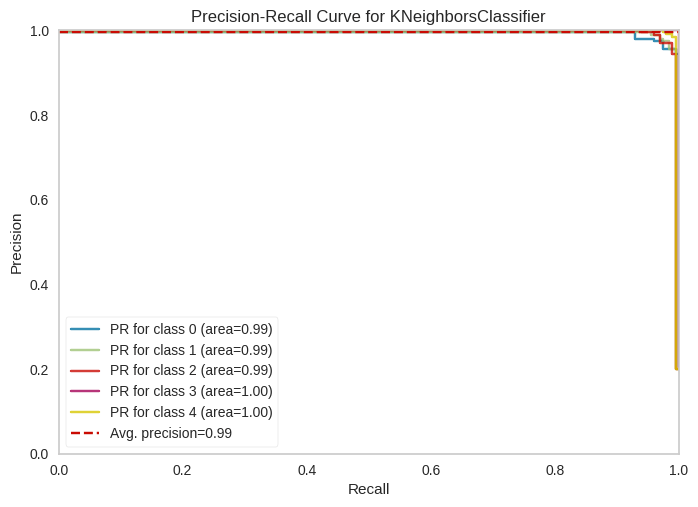

<Axes: title={'center': 'Precision-Recall Curve for KNeighborsClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    knc_aug,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель справилась идеально.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_knc_aug[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.2857
Класс 1: оптимальный порог = 0.1429
Класс 2: оптимальный порог = 0.4286
Класс 3: оптимальный порог = 0.8571
Класс 4: оптимальный порог = 0.1429


$\large\text{Строим график обучения модели:}$

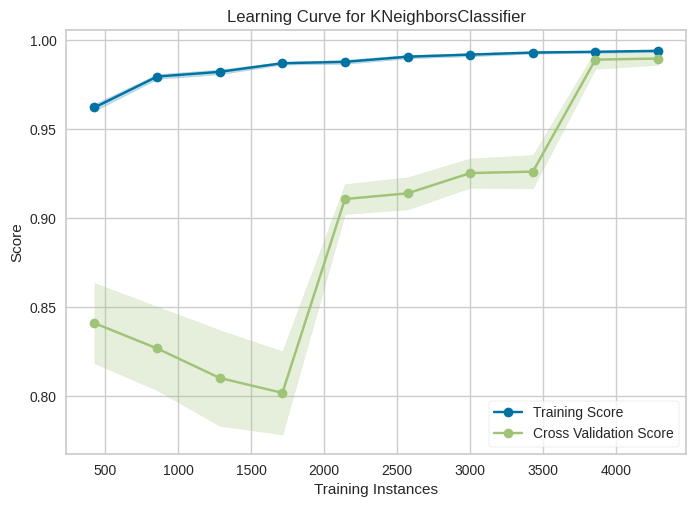

<Axes: title={'center': 'Learning Curve for KNeighborsClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    KNC_pipeline_aug,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X_aug, y_aug)
visualizer.show()

$\large\text{График показывает, что модель немного переобучилась, так как есть разрыв между значениями accuracy train'а и CV на малых значениях выборки.}$

### $\textbf{MLPClassifier}$

$\large\text{Создаем pipeline для MLPClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
MLPC_pipeline_aug = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(100, 50, 25, 5), max_iter=10000, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_mlp_aug = cross_validate(
    estimator=MLPC_pipeline_aug,
    X=X_aug, y=y_aug,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_mlp_aug.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9956
train_accuracy: 0.9982
test_f1_weighted: 0.9956
train_f1_weighted: 0.9982
test_precision_weighted: 0.9956
train_precision_weighted: 0.9982
test_recall_weighted: 0.9956
train_recall_weighted: 0.9982


$\large\text{По результатам кросс-валидации модель работает почти идеально.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

mlp_aug = MLPC_pipeline_aug.fit(X_train, y_train)

finish = time.time()
mlp_time_aug = finish - start
print(f'Education time: {mlp_time_aug:.6f}')

Education time: 5.290060


$\large\text{Выводим accuracy модели:}$

In [ ]:
mlp_score_aug = mlp_aug.score(X_test, y_test)
print(f'{mlp_score_aug:.4f}')

0.9950


$\large\text{Accuracy практически равна 1, это показатель идеальной модели.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

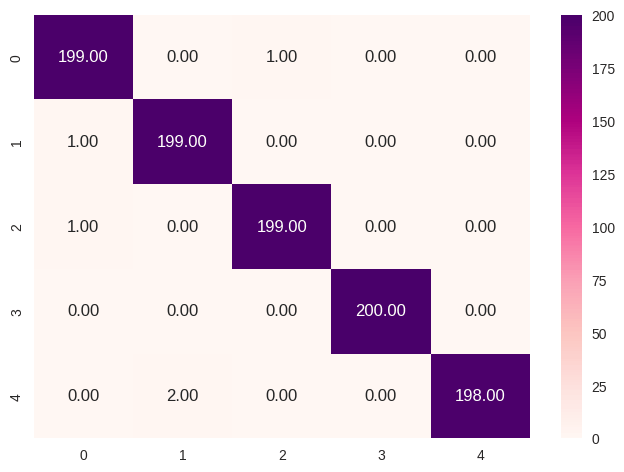

In [ ]:
y_test_pred_mlp_aug = mlp_aug.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_mlp_aug), cmap='RdPu', annot=True, fmt='.2f')

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 1 ошибка,}$ <br>
$\large\text{1 класс - 1 ошибка,}$ <br>
$\large\text{2 класс - 1 ошибка,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - нет ошибок}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_mlp_aug))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       200
           1       0.99      0.99      0.99       200
           2       0.99      0.99      0.99       200
           3       1.00      1.00      1.00       200
           4       1.00      0.99      0.99       200

    accuracy                           0.99      1000
   macro avg       1.00      0.99      1.00      1000
weighted avg       1.00      0.99      1.00      1000



$\large\text{Отчет показывает, что модель идеально справилась с предсказанием принадлежность к классам.}$

$\large\text{Строим кривые ROC-AUC:}$

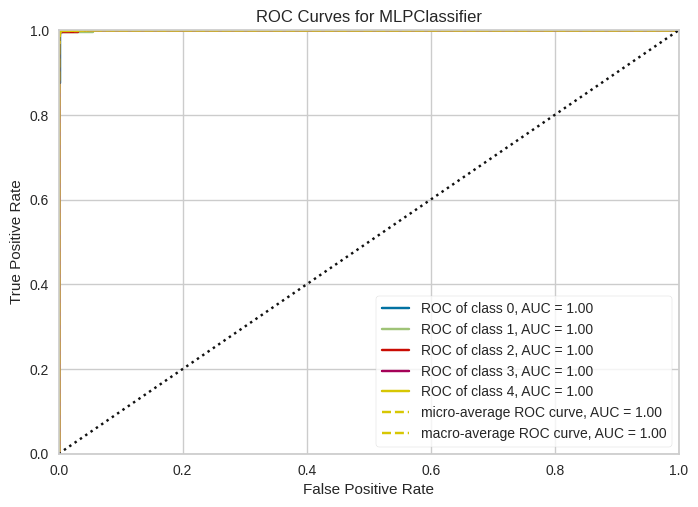

<Axes: title={'center': 'ROC Curves for MLPClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(mlp_aug)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_mlp_aug = mlp_aug.predict_proba(X_test)
unique_classes = np.unique(y_aug)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_mlp_aug[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.9996
Класс '1': AUC = 0.9997
Класс '2': AUC = 0.9998
Класс '3': AUC = 1.0000
Класс '4': AUC = 1.0000


$\large\text{График показывает, что модель справилась идеально.}$

$\large\text{Строим кривые Precision-Recall:}$

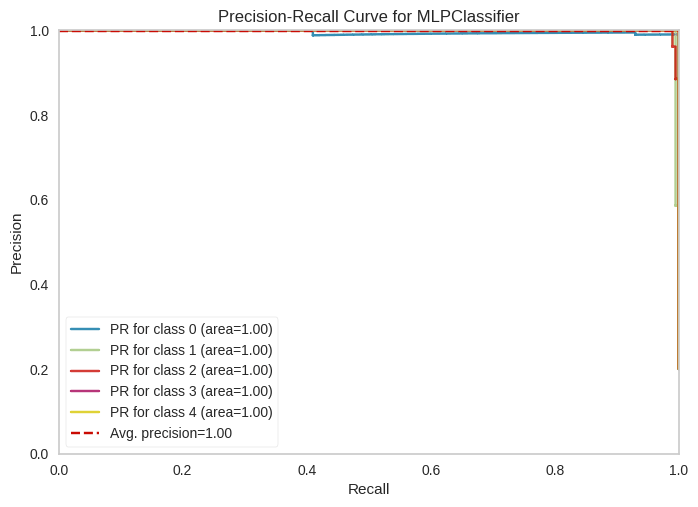

<Axes: title={'center': 'Precision-Recall Curve for MLPClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    mlp_aug,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель так же справилась идеально.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_mlp_aug[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.0663
Класс 1: оптимальный порог = 0.5674
Класс 2: оптимальный порог = 0.6513
Класс 3: оптимальный порог = 0.9999
Класс 4: оптимальный порог = 0.3168


$\large\text{Строим график обучения модели:}$

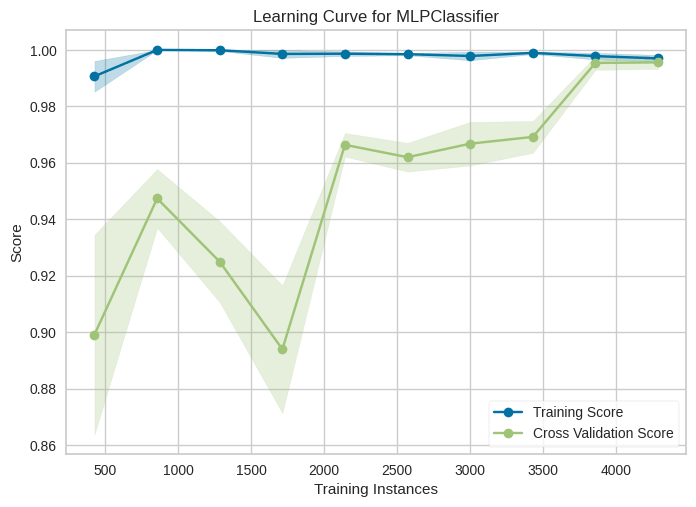

<Axes: title={'center': 'Learning Curve for MLPClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    MLPC_pipeline_aug,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X_aug, y_aug)
visualizer.show()

$\large\text{График демонстрирует небольшое переобучение модели на малых значениях выборки.}$

### $\textbf{RandomForestClassifier}$

$\large\text{Создаем pipeline для RandomForestClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
RFC_pipeline_aug = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, max_depth=7, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_forest_aug = cross_validate(
    estimator=RFC_pipeline_aug,
    X=X_aug, y=y_aug,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_forest_aug.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9860
train_accuracy: 0.9897
test_f1_weighted: 0.9859
train_f1_weighted: 0.9896
test_precision_weighted: 0.9865
train_precision_weighted: 0.9899
test_recall_weighted: 0.9860
train_recall_weighted: 0.9897


$\large\text{По результатам кросс-валидации модель работает практически идельно, пере- и недообучение отсутствует.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

forest_aug = RFC_pipeline_aug.fit(X_train, y_train)

finish = time.time()
forest_time_aug = finish - start
print(f'Education time: {forest_time_aug:.6f}')

Education time: 0.529140


$\large\text{Выводим accuracy модели:}$

In [ ]:
forest_score_aug = forest_aug.score(X_test, y_test)
print(f'{forest_score_aug:.4f}')

0.9900


$\large\text{Accuracy практически равна 1, это показатель идеальной модели.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

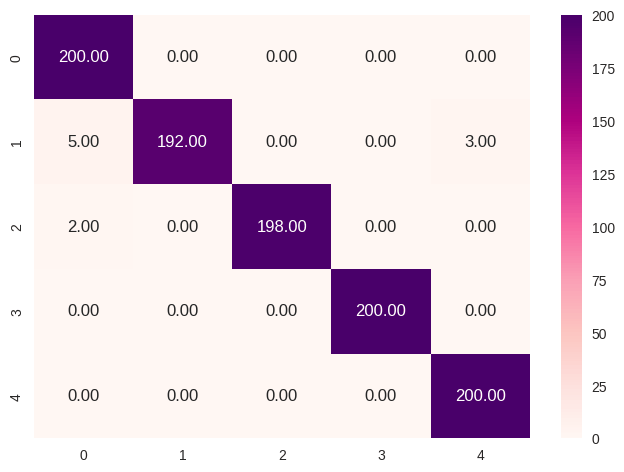

In [ ]:
y_test_pred_forest_aug = forest_aug.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_forest_aug), cmap='RdPu', annot=True, fmt='.2f')

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - нет ошибок,}$ <br>
$\large\text{1 класс - 8 ошибок,}$ <br>
$\large\text{2 класс - 2 ошибки,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс- нет ошибок}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_forest_aug))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98       200
           1       1.00      0.96      0.98       200
           2       1.00      0.99      0.99       200
           3       1.00      1.00      1.00       200
           4       0.99      1.00      0.99       200

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



$\large\text{Отчет показывает, что модель идеально предсказывает принадлежность к классам.}$

$\large\text{Строим кривые ROC-AUC:}$

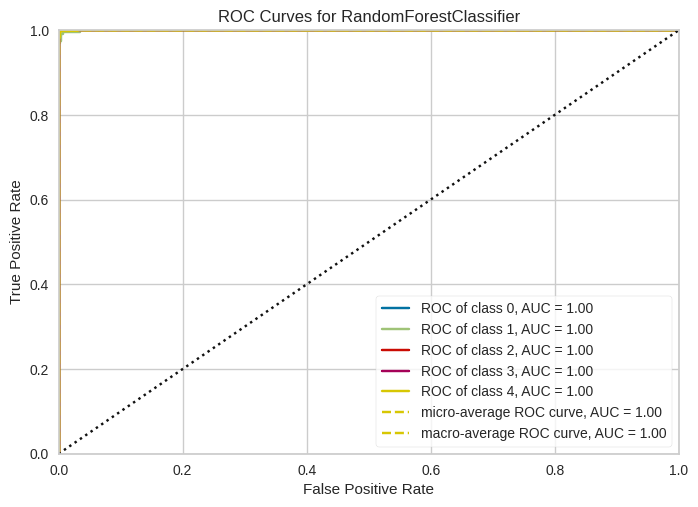

<Axes: title={'center': 'ROC Curves for RandomForestClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(forest_aug)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_forest_aug = forest_aug.predict_proba(X_test)
unique_classes = np.unique(y_aug)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_forest_aug[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 1.0000
Класс '1': AUC = 0.9997
Класс '2': AUC = 1.0000
Класс '3': AUC = 1.0000
Класс '4': AUC = 1.0000


$\large\text{График показывает, что модель справилась идеально.}$

$\large\text{Строим кривые Precision-Recall:}$

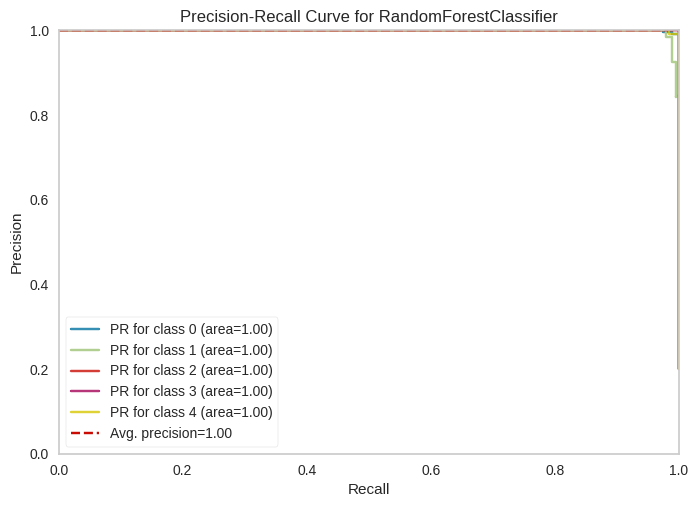

<Axes: title={'center': 'Precision-Recall Curve for RandomForestClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    forest_aug,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель работает идеально.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_forest_aug[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.6263
Класс 1: оптимальный порог = 0.2333
Класс 2: оптимальный порог = 0.3749
Класс 3: оптимальный порог = 0.9479
Класс 4: оптимальный порог = 0.6089


$\large\text{Строим график обучения модели:}$

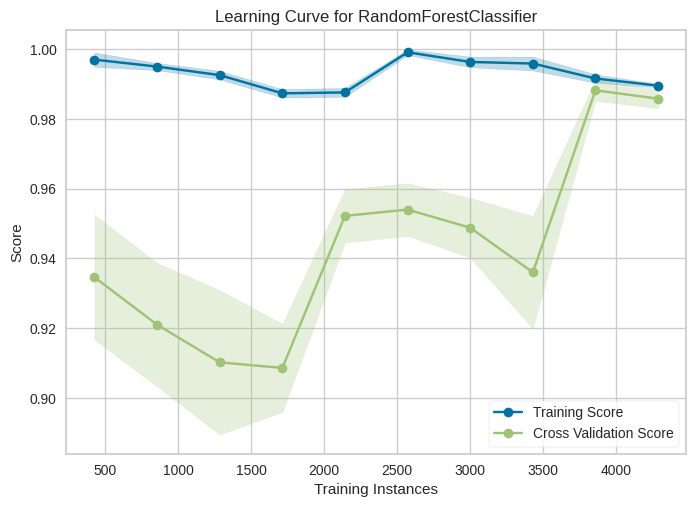

<Axes: title={'center': 'Learning Curve for RandomForestClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    RFC_pipeline_aug,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X_aug, y_aug)
visualizer.show()

$\large\text{График демонстрирует, что модель немного переобучается на малых значениях выборки.}$

### $\textbf{SVC}$

$\large\text{Создаем pipeline для SVC: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
SVC_pipeline_aug = make_pipeline(StandardScaler(), SVC(C=7, max_iter=10000, kernel='rbf', probability=True, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_svc_aug = cross_validate(
    estimator=SVC_pipeline_aug,
    X=X_aug, y=y_aug,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_svc_aug.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9574
train_accuracy: 0.9569
test_f1_weighted: 0.9570
train_f1_weighted: 0.9566
test_precision_weighted: 0.9632
train_precision_weighted: 0.9627
test_recall_weighted: 0.9574
train_recall_weighted: 0.9569


$\large\text{По результатам кросс-валидации видим, что произошла аномалия и значение accuracy на CV больше, чем на train'е.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

svc_aug = SVC_pipeline_aug.fit(X_train, y_train)

finish = time.time()
svc_time_aug = finish - start
print(f'Education time: {svc_time_aug:.6f}')

Education time: 0.353280


$\large\text{Выводим accuracy модели:}$

In [ ]:
svc_score_aug = svc_aug.score(X_test, y_test)
print(f'{svc_score_aug:.4f}')

0.9590


$\large\text{Accuracy практически равна 1, это показатель идеальной модели.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

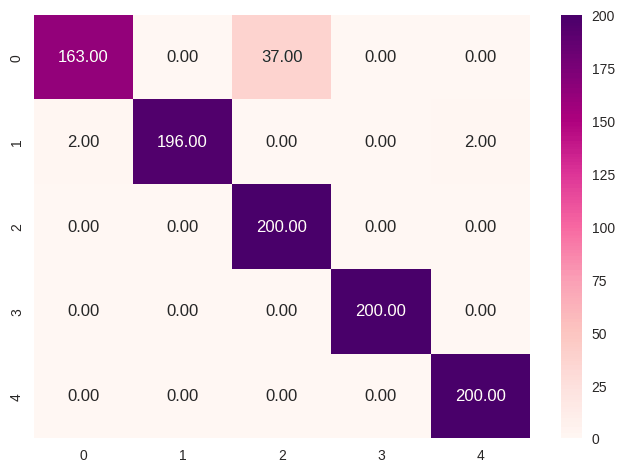

In [ ]:
y_test_pred_svc_aug = svc_aug.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_svc_aug), cmap='RdPu', annot=True, fmt='.2f')

$\large\text{Матрица показывает, что модель совершила ошибки при преджсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 37 ошибок,}$ <br>
$\large\text{1 класс - 4 ошибки,}$ <br>
$\large\text{2 класс - нет ошибок,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - нет ошибок}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_svc_aug))

              precision    recall  f1-score   support

           0       0.99      0.81      0.89       200
           1       1.00      0.98      0.99       200
           2       0.84      1.00      0.92       200
           3       1.00      1.00      1.00       200
           4       0.99      1.00      1.00       200

    accuracy                           0.96      1000
   macro avg       0.96      0.96      0.96      1000
weighted avg       0.96      0.96      0.96      1000



$\large\text{Отчет показывает, что модель работает практически идеально.}$

$\large\text{Строим кривые ROC-AUC:}$

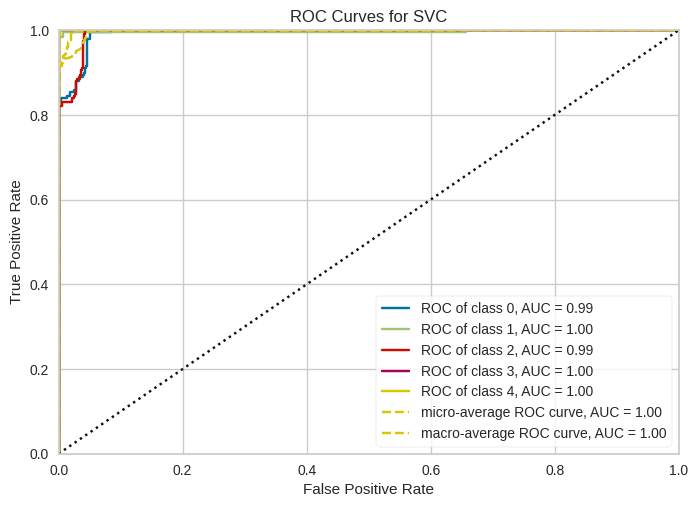

<Axes: title={'center': 'ROC Curves for SVC'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(svc_aug)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_svc_aug = svc_aug.predict_proba(X_test)
unique_classes = np.unique(y_aug)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_svc_aug[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.9928
Класс '1': AUC = 0.9967
Класс '2': AUC = 0.9938
Класс '3': AUC = 1.0000
Класс '4': AUC = 1.0000


$\large\text{График показывает, что модель работает отлично.}$

$\large\text{Строим кривые Precision-Recall:}$

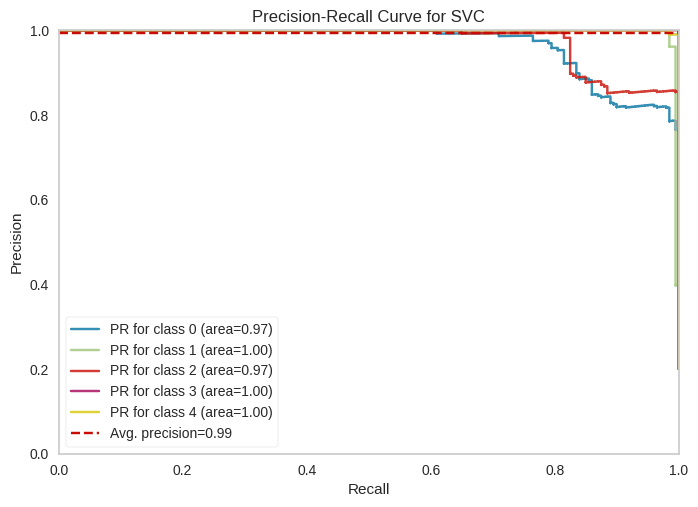

<Axes: title={'center': 'Precision-Recall Curve for SVC'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    svc_aug,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель отлично предсказывает классы.}$

$\large\text{Находим оптимальные пороги для каждого:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_svc_aug[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.1700
Класс 1: оптимальный порог = 0.1793
Класс 2: оптимальный порог = 0.3184
Класс 3: оптимальный порог = 0.9881
Класс 4: оптимальный порог = 0.4467


$\large\text{Строим график обучения модели:}$


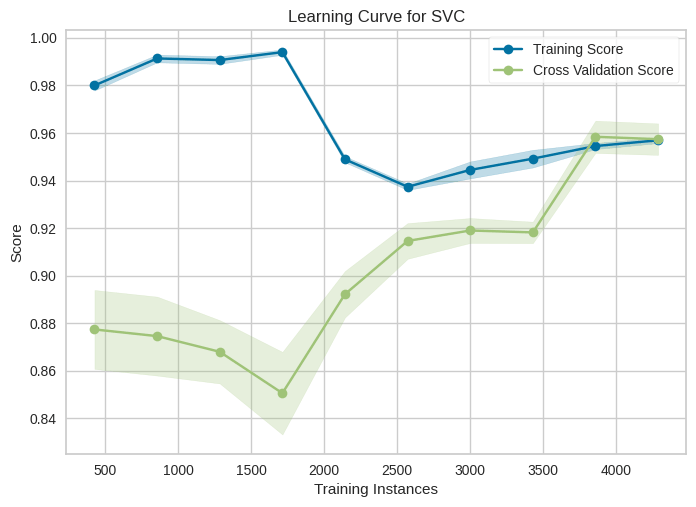

<Axes: title={'center': 'Learning Curve for SVC'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    SVC_pipeline_aug,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X_aug, y_aug)
visualizer.show()

$\large\text{Наблюдаем небольшое переобучение на малых значениях выборки.}$

### $\textbf{GaussianNB}$

$\large\text{Создаем pipeline для GaussianNB: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
GNB_pipeline_aug = make_pipeline(StandardScaler(), GaussianNB())

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_gnb_aug = cross_validate(
    estimator=GNB_pipeline_aug,
    X=X_aug, y=y_aug,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_gnb_aug.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.7984
train_accuracy: 0.7980
test_f1_weighted: 0.8011
train_f1_weighted: 0.8010
test_precision_weighted: 0.8743
train_precision_weighted: 0.8739
test_recall_weighted: 0.7984
train_recall_weighted: 0.7980


$\large\text{По результатам кросс-валидации видим, что произошла аномалия и значение accuracy на CV больше, чем на train'е.}$
$\large\text{Также значения не особо высокие и близки друг другу, это похоже на недообучение.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

gnb_aug = GNB_pipeline_aug.fit(X_train, y_train)

finish = time.time()
gnb_time_aug = finish - start
print(f'Education time: {gnb_time_aug:.6f}')

Education time: 0.009304


$\large\text{Выводим accuracy модели:}$

In [ ]:
gnb_score_aug = gnb_aug.score(X_test, y_test)
print(f'{gnb_score_aug:.4f}')

0.8100


$\large\text{Accuracy равна 0,81, это показатель достаточно хорошей модели.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

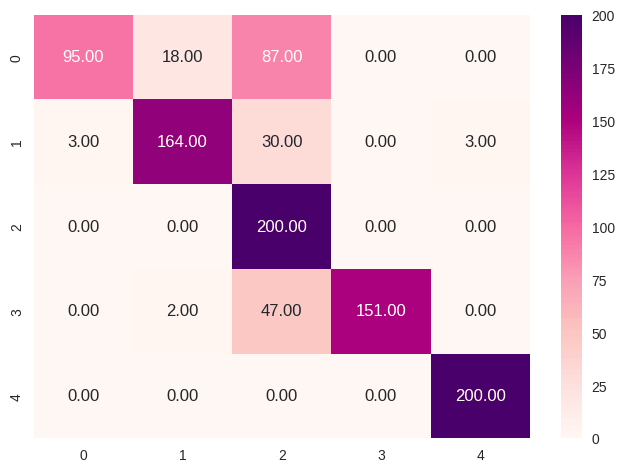

In [ ]:
y_test_pred_gnb_aug = gnb_aug.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_gnb_aug), cmap='RdPu', annot=True, fmt='.2f')

$\large\text{Матрица показывает, что модель совершила ошибки при предсказании принадлежности к классам:}$ <br>
$\large\text{0 класс - 105 ошибок,}$ <br>
$\large\text{1 класс - 36 ошибок,}$ <br>
$\large\text{2 класс - нет ошибок,}$ <br>
$\large\text{3 класс - 49 ошибок,}$ <br>
$\large\text{4 класс - нет ошибок}$ <br>

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_gnb_aug))

              precision    recall  f1-score   support

           0       0.97      0.47      0.64       200
           1       0.89      0.82      0.85       200
           2       0.55      1.00      0.71       200
           3       1.00      0.76      0.86       200
           4       0.99      1.00      0.99       200

    accuracy                           0.81      1000
   macro avg       0.88      0.81      0.81      1000
weighted avg       0.88      0.81      0.81      1000



$\large\text{Отчет показывает, что модель с некоторыми классами (0 и 2) справилась гораздо хуже, чем к другими.}$

$\large\text{Строим кривые ROC-AUC:}$

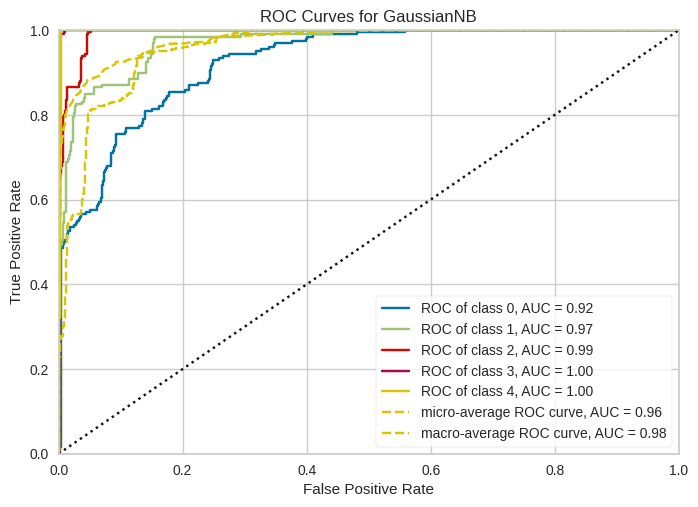

<Axes: title={'center': 'ROC Curves for GaussianNB'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(gnb_aug)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_gnb_aug = gnb_aug.predict_proba(X_test)
unique_classes = np.unique(y_aug)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_gnb_aug[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 0.9242
Класс '1': AUC = 0.9703
Класс '2': AUC = 0.9924
Класс '3': AUC = 0.9999
Класс '4': AUC = 0.9980


$\large\text{График показывает, что модель работает практически идеально.}$

$\large\text{Строим кривые Precision-Recall:}$

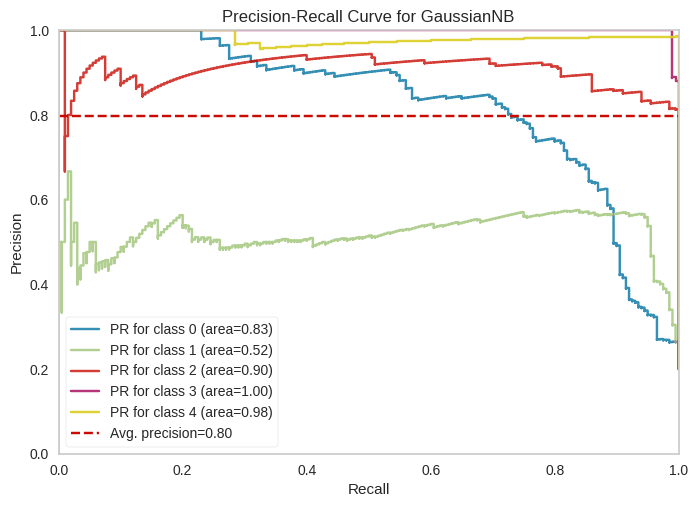

<Axes: title={'center': 'Precision-Recall Curve for GaussianNB'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    gnb_aug,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель плохо справилась с предсказанием принадлежности к 1 классу.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_gnb_aug[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.0000
Класс 1: оптимальный порог = 0.0002
Класс 2: оптимальный порог = 1.0000
Класс 3: оптимальный порог = 0.0003
Класс 4: оптимальный порог = 1.0000


$\large\text{Строим график обучения модели:}$

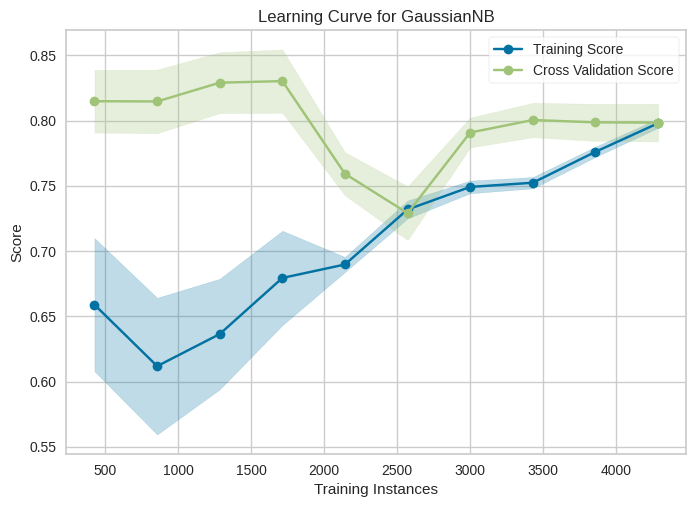

<Axes: title={'center': 'Learning Curve for GaussianNB'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    GNB_pipeline_aug,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X_aug, y_aug)
visualizer.show()

$\large\text{Наблюдаем явное недообучение, причем значения на train'е меньше, чем на test'е, что является аномалией.}$

### $\textbf{GradientBoostingClassifier}$

$\large\text{Создаем pipeline для GradientBoostingClassifier: сначала стандартизируем данные, потом обучаем модель.}$

In [ ]:
GBC_pipeline_aug = make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, max_features=0.7, subsample=0.8, random_state=42))

$\large\text{Проводим кросс-валидацию:}$

In [ ]:
cv_results_gbc_aug = cross_validate(
    estimator=GBC_pipeline_aug,
    X=X, y=y,
    cv=skf,
    scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'],
    n_jobs=-1,
    return_train_score=True
)

for key, value in cv_results_gbc_aug.items():
    if key.startswith('test_') or key.startswith('train_'):
        print(f"{key}: {value.mean():.4f}")

test_accuracy: 0.9399
train_accuracy: 1.0000
test_f1_weighted: 0.9345
train_f1_weighted: 1.0000
test_precision_weighted: 0.9383
train_precision_weighted: 1.0000
test_recall_weighted: 0.9399
train_recall_weighted: 1.0000


$\large\text{По результатам кросс-валидации значение accuracy на train'е равно 1, а на test'е - 0,94.}$
$\large\text{Возникает предпроложение о переобучении.}$

$\large\text{Обучаем модель и засекаем время ее обучения:}$

In [ ]:
start = time.time()

gbc_aug = GBC_pipeline_aug.fit(X_train, y_train)

finish = time.time()
gbc_time_aug = finish - start
print(f'Education time: {gbc_time_aug:.6f}')

Education time: 17.798864


$\large\text{Выводим accuracy модели:}$

In [ ]:
gbc_score_aug = gbc_aug.score(X_test, y_test)
print(f'{gbc_score_aug:.4f}')

0.9960


$\large\text{Accuracy практически равна 1, это показатель идеальной модели.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

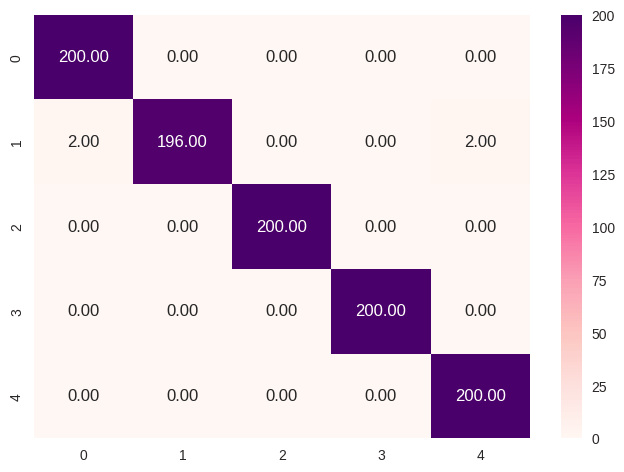

In [ ]:
y_test_pred_gbc_aug = gbc_aug.predict(X_test)
sns.heatmap(confusion_matrix(y_test, y_test_pred_gbc_aug), cmap='RdPu', annot=True, fmt='.2f')

$\large\text{Матрица ошибок показывает, что модель совершила только 4 ошибки при предсказании 1 класса.}$

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_test, y_test_pred_gbc_aug))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       200
           1       1.00      0.98      0.99       200
           2       1.00      1.00      1.00       200
           3       1.00      1.00      1.00       200
           4       0.99      1.00      1.00       200

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



$\large\text{Отчет показывает, что модель работает идеально.}$

$\large\text{Строим кривые ROC-AUC:}$

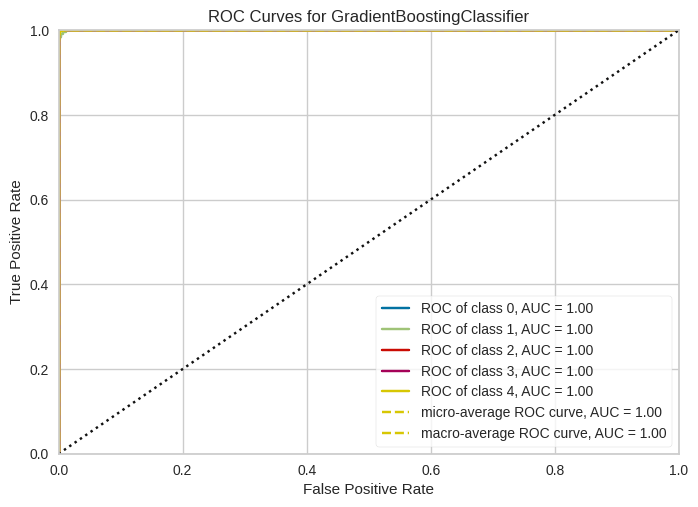

<Axes: title={'center': 'ROC Curves for GradientBoostingClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [ ]:
visualizer = ROCAUC(gbc_aug)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)

visualizer.show()

In [ ]:
y_pred_proba_gbc_aug = gbc_aug.predict_proba(X_test)
unique_classes = np.unique(y_aug)

auc_scores = {}
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    auc = roc_auc_score(y_bin, y_pred_proba_gbc_aug[:, i])
    auc_scores[cls] = auc
    print(f"Класс '{cls}': AUC = {auc:.4f}")

Класс '0': AUC = 1.0000
Класс '1': AUC = 0.9999
Класс '2': AUC = 1.0000
Класс '3': AUC = 1.0000
Класс '4': AUC = 1.0000


$\large\text{График показывает, что модель идеально справилась с предсказанием.}$

$\large\text{Строим кривые Precision-Recall:}$

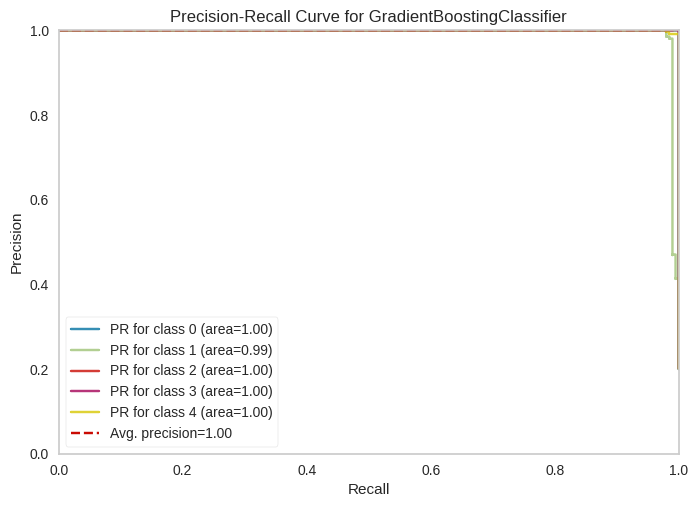

<Axes: title={'center': 'Precision-Recall Curve for GradientBoostingClassifier'}, xlabel='Recall', ylabel='Precision'>

In [ ]:
visualizer = PrecisionRecallCurve(
    gbc_aug,
    classes=unique_classes,
    per_class=True,
    micro=False,
    fill_area=True,
    ap_score=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.show()

$\large\text{График показывает, что модель работает идеально.}$

$\large\text{Находим оптимальные пороги для каждого класса:}$

In [ ]:
for i, cls in enumerate(unique_classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, thresholds = roc_curve(y_bin, y_pred_proba_gbc_aug[:, i])
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]

    print(f"Класс {cls}: оптимальный порог = {optimal_threshold:.4f}")

Класс 0: оптимальный порог = 0.9997
Класс 1: оптимальный порог = 0.0001
Класс 2: оптимальный порог = 0.9176
Класс 3: оптимальный порог = 1.0000
Класс 4: оптимальный порог = 0.9137


$\large\text{Строим график обучения модели:}$

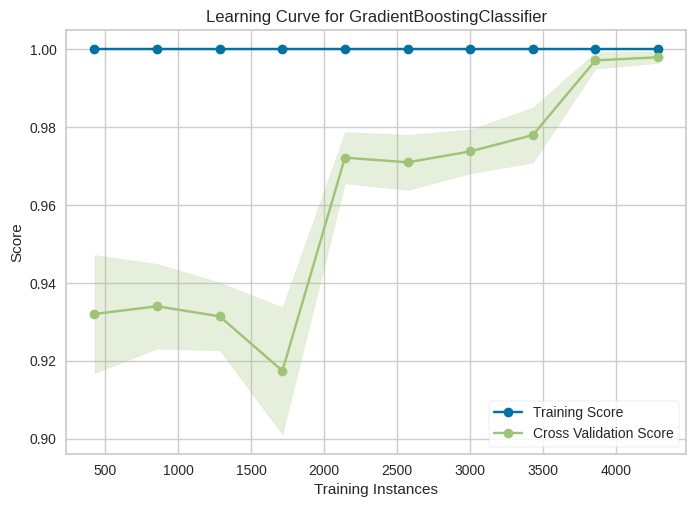

<Axes: title={'center': 'Learning Curve for GradientBoostingClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    GBC_pipeline_aug,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
visualizer.fit(X_aug, y_aug)
visualizer.show()

$\large\text{Наблюдаем явное переобучение, так как значение accuracy на train'е всегда равно 1.}$

### $\large\textbf{Выводы}$

$\large\text{Строим сводную таблицу по всем моделям и выбираем лучшую:}$

In [ ]:
results = {
    'Logistic Regression': {
        'Accuracy': cv_results_LR_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_LR_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_LR_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_LR_aug['test_recall_weighted'].mean(),
        'Train Time (s)': LR_aug_time,
        'Overfitting Gap (Acc)': LR_aug_score - cv_results_LR_aug['test_accuracy'].mean()
    },
    'Decision Tree Classifier': {
        'Accuracy': cv_results_tree_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_tree_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_tree_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_tree_aug['test_recall_weighted'].mean(),
        'Train Time (s)': tree_aug_time,
        'Overfitting Gap (Acc)': tree_aug_score - cv_results_tree_aug['test_accuracy'].mean()
    },
    'KNN Classifier': {
        'Accuracy': cv_results_knc_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_knc_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_knc_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_knc_aug['test_recall_weighted'].mean(),
        'Train Time (s)': knc_time_aug,
        'Overfitting Gap (Acc)': knc_score_aug - cv_results_knc_aug['test_accuracy'].mean()
    },
    'MLP Classifier': {
        'Accuracy': cv_results_mlp_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_mlp_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_mlp_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_mlp_aug['test_recall_weighted'].mean(),
        'Train Time (s)': mlp_time_aug,
        'Overfitting Gap (Acc)': mlp_score_aug - cv_results_mlp_aug['test_accuracy'].mean()
    },
    'Random Forest Classifier': {
        'Accuracy': cv_results_forest_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_forest_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_forest_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_forest_aug['test_recall_weighted'].mean(),
        'Train Time (s)': forest_time_aug,
        'Overfitting Gap (Acc)': forest_score_aug - cv_results_forest_aug['test_accuracy'].mean()
    },

    'SVC (RBF)': {
        'Accuracy': cv_results_svc_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_svc_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_svc_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_svc_aug['test_recall_weighted'].mean(),
        'Train Time (s)': svc_time_aug,
        'Overfitting Gap (Acc)': svc_score_aug - cv_results_svc_aug['test_accuracy'].mean()
    },
    'GaussianNB': {
        'Accuracy': cv_results_gnb_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_gnb_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_gnb_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_gnb_aug['test_recall_weighted'].mean(),
        'Train Time (s)': gnb_time_aug,
        'Overfitting Gap (Acc)': gnb_score_aug - cv_results_gnb_aug['test_accuracy'].mean()
    },
    'GradientBoostingClassifier': {
        'Accuracy': cv_results_gbc_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_gbc_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_gbc_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_gbc_aug['test_recall_weighted'].mean(),
        'Train Time (s)': gbc_time_aug,
        'Overfitting Gap (Acc)': gbc_score_aug - cv_results_gbc_aug['test_accuracy'].mean()
    }
}

df_results = pd.DataFrame(results).T

positive_values = df_results[df_results['Overfitting Gap (Acc)'] > 0]['Overfitting Gap (Acc)']
min_positive = positive_values.min()
max_positive = positive_values.max()

df_results = df_results.round(4)

styled_df = df_results.style.background_gradient(cmap='Blues', subset=['Accuracy', 'F1 Weighted', 'Precision Weighted', 'Recall Weighted']) \
                            .background_gradient(cmap='Greens_r', subset=['Overfitting Gap (Acc)'], vmin=min_positive, vmax=max_positive) \
                            .background_gradient(cmap='Reds', subset=['Train Time (s)']) \
                            .format(precision=4) \
                            .set_caption("Сводная таблица метрик моделей после аугментации данных") \
                            .set_table_styles([{
                                'selector': 'caption',
                                'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'center')]
                            }])

styled_df = styled_df.applymap(
    lambda x: 'background-color: #d3d3d3' if isinstance(x, (int, float)) and x < 0 else '',
    subset=['Overfitting Gap (Acc)']
)

display(styled_df)

,Accuracy,F1 Weighted,Precision Weighted,Recall Weighted,Train Time (s),Overfitting Gap (Acc)
Logistic Regression,0.9270,0.9269,0.9293,0.9270,0.2801,0.0060
Decision Tree Classifier,0.9504,0.9504,0.9535,0.9504,0.0216,0.0136
KNN Classifier,0.9898,0.9898,0.9899,0.9898,0.0119,-0.0048
MLP Classifier,0.9956,0.9956,0.9956,0.9956,5.2901,-0.0006
Random Forest Classifier,0.9860,0.9859,0.9865,0.9860,0.5291,0.0040
SVC (RBF),0.9574,0.9570,0.9632,0.9574,0.3533,0.0016
GaussianNB,0.7984,0.8011,0.8743,0.7984,0.0093,0.0116
GradientBoostingClassifier,0.9399,0.9345,0.9383,0.9399,17.7989,0.0561


$\large\text{Серый цвет в колонке Overfitting Gap означает, что точность на валидации оказалась выше, чем на обучении. Это не всегда значит,}$
$\large\text{что модель недо- или переобучена, просто требуется проверка данных или разбиения выборки.}$
$\large\text{В нашем случае, возможно, произошла аномалия, которая и привела к таким показателям.}$

$\large\text{Сравнивая метрики всех моделей, самой лучшей оказалась MLPClassifier с параметрами:}$ <br>
$\large\text{Accuracy = 0,9956,}$ <br>
$\large\text{F1 Weighted = 0,9956,}$ <br>
$\large\text{Precision Weighted = 0,9956,}$ <br>
$\large\text{Recall Weighted = 0,9956}$ <br>

$\large\text{Выбираем данную модель для настройки гиперпараметров для ее улучшения.}$

### $\large\textbf{Настройка гиперпараметров лучшей модели}$

$\large\text{Разбиваем данные на обучающую, тестовую и валидационную выборки:}$

In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(X_aug, y_aug, test_size=0.2, random_state=42, stratify=y_aug)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

$\large\text{Для подбора гиперпараметров будем также использовать Bayesian Optimization.}$

$\large\text{Создаем целевую функцию - то, что optuna будет оптимизировать. Аргумент 'trial' - объект, который предлагает значения гиперпараметров на каждой итерации.}$

$\large\text{Пояснения по функции:}$ <br>
$\large\text{trial.suggest_float - предлагает численные значения с плавающей точкой,}$ <br>
$\large\text{trial.suggest_categorical - количество признаков для поиска лучшего разделения}$ <br>
$\large\text{В конце возвращаем среднее значение accuracy по кросс-валидации.}$

In [ ]:
def objective_mlp(trial):
    pipeline = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical('hidden_layer_sizes',
                [(100,50,25), (100,100,50), (150,100,50), (100,50), (200,100,50), (100, 50, 25, 5), (200, 100, 50, 25, 5)]),
            alpha=trial.suggest_float('alpha', 1e-5, 1e-2, log=True),
            learning_rate_init=trial.suggest_float('lr', 1e-4, 1e-2, log=True),
            batch_size=trial.suggest_categorical('batch_size', [32, 64, 128]),
            max_iter=5000,
            early_stopping=True,
            random_state=42
        )
    )
    return cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='accuracy').mean()

$\large\text{Создаем объект исследования study:}$ <br>
$\large\text{optuna.samplers.TPESampler - алгоритм байесовской оптимизации (Tree-structured Parzen Estimator - эффективный алгоритм байесовской оптимизации,}$
$\large\text{он моделирует распределение "хороших" и "плохих" гиперпараметров).}$ <br>
$\large\text{Запускаем оптимизацию:}$

In [ ]:
study_mlp = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_mlp.optimize(objective_mlp, n_trials=100, show_progress_bar=True)

[I 2026-05-12 16:40:44,491] A new study created in memory with name: no-name-36b1d6f5-fc21-4e4a-b086-ed8c9cc1cb5d


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-05-12 16:41:02,495] Trial 0 finished with value: 0.9846656458805991 and parameters: {'hidden_layer_sizes': (100, 100, 50), 'alpha': 0.003967605077052989, 'lr': 0.0015930522616241021, 'batch_size': 128}. Best is trial 0 with value: 0.9846656458805991.
[I 2026-05-12 16:41:16,508] Trial 1 finished with value: 0.9883348738488926 and parameters: {'hidden_layer_sizes': (100, 50, 25), 'alpha': 7.476312062252303e-05, 'lr': 0.0016738085788752138, 'batch_size': 128}. Best is trial 1 with value: 0.9883348738488926.
[I 2026-05-12 16:41:46,528] Trial 2 finished with value: 0.9349956896685869 and parameters: {'hidden_layer_sizes': (100, 100, 50), 'alpha': 3.247673570627447e-05, 'lr': 0.00013492834268013249, 'batch_size': 64}. Best is trial 1 with value: 0.9883348738488926.
[I 2026-05-12 16:42:28,372] Trial 3 finished with value: 0.9863353157745681 and parameters: {'hidden_layer_sizes': (150, 100, 50), 'alpha': 0.00534516611064682, 'lr': 0.00032927591344236165, 'batch_size': 32}. Best is tria

$\large\text{Выводим лучшее значение по кросс-валидации и параметры лучшей комбинации:}$

In [ ]:
print(f"Best CV: {study_mlp.best_value:.4f}")
print(f"Best params: {study_mlp.best_params}")

Best CV: 0.9950
Best params: {'hidden_layer_sizes': (150, 100, 50), 'alpha': 0.0011550988043181733, 'lr': 0.006207788871873935, 'batch_size': 128}


$\large\text{Создаем модель с наилучшими параметрами, обучаем ее и предсказываем значения на валидационной выборке:}$

In [ ]:
best_mlp = MLPClassifier(
    hidden_layer_sizes = study_mlp.best_params['hidden_layer_sizes'],
    alpha = study_mlp.best_params['alpha'],
    learning_rate_init = study_mlp.best_params['lr'],
    batch_size = study_mlp.best_params['batch_size'],
    activation = study_mlp.best_params.get('activation', 'relu'),
    solver = study_mlp.best_params.get('solver', 'adam'),
    max_iter=5000,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

best_pipeline_mlp = make_pipeline(StandardScaler(), best_mlp)
best_pipeline_mlp.fit(X_train, y_train)

y_pred_train_mlp = best_pipeline_mlp.predict(X_train)
y_pred_val_mlp = best_pipeline_mlp.predict(X_val)

train_acc_mlp = accuracy_score(y_train, y_pred_train_mlp)
val_acc_mlp = accuracy_score(y_val, y_pred_val_mlp)

print(f"Train Accuracy: {train_acc_mlp:.4f}")
print(f"Validation Accuracy: {val_acc_mlp:.4f}")
print(f"Gap: {train_acc_mlp - val_acc_mlp:.4f}")
print(f"F1-weighted: {f1_score(y_val, y_pred_val_mlp, average='weighted'):.4f}")
print(f"Precision-weighted: {precision_score(y_val, y_pred_val_mlp, average='weighted'):.4f}")
print(f"Recall-weighted: {recall_score(y_val, y_pred_val_mlp, average='weighted'):.4f}")

Train Accuracy: 0.9923
Validation Accuracy: 0.9890
Gap: 0.0033
F1-weighted: 0.9890
Precision-weighted: 0.9893
Recall-weighted: 0.9890


$\large\text{Разрыв между Train Accuracy и Validation Accuracy совсем небольшой, всего 0,03, следовательно, пере- и недообучение отсуствует.}$
$\large\text{Остальные метрики так же имеют высокие показатели.}$

$\large\text{Выводим отчет по классификации:}$

In [ ]:
print(classification_report(y_val, y_pred_val_mlp, digits=4))

              precision    recall  f1-score   support

           0     1.0000    0.9950    0.9975       200
           1     0.9567    0.9950    0.9755       200
           2     0.9950    1.0000    0.9975       200
           3     1.0000    1.0000    1.0000       200
           4     0.9948    0.9550    0.9745       200

    accuracy                         0.9890      1000
   macro avg     0.9893    0.9890    0.9890      1000
weighted avg     0.9893    0.9890    0.9890      1000



$\large\text{Отчет показывает, что модель идеально справилась с предсказанием принадлежности к классам.}$

$\large\text{Строим матрицу ошибок:}$

<Axes: >

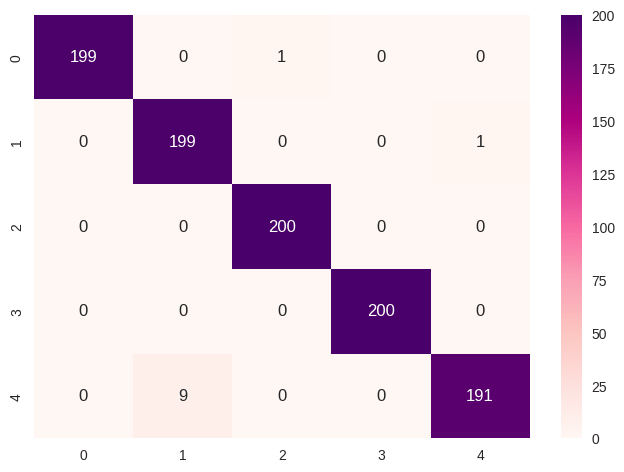

In [ ]:
sns.heatmap(confusion_matrix(y_val, y_pred_val_mlp), cmap='RdPu', fmt='d', annot=True)

$\large\text{Матрица показывает, что модель совершила несколько ошибок:}$ <br>
$\large\text{0 класс - 1 ошибка,}$ <br>
$\large\text{1 класс - 1 ошибка,}$ <br>
$\large\text{2 класс - нет ошибок,}$ <br>
$\large\text{3 класс - нет ошибок,}$ <br>
$\large\text{4 класс - 9 ошибок}$ <br>

$\large\text{Строим график обучения модели:}$

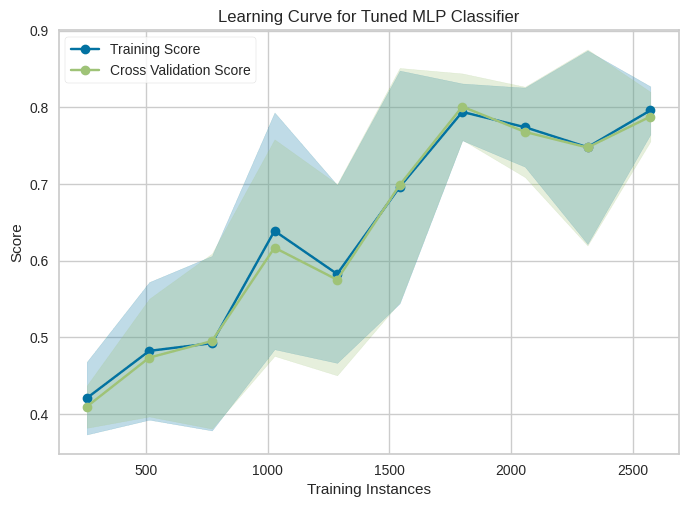

<Axes: title={'center': 'Learning Curve for Tuned MLP Classifier'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
visualizer = LearningCurve(
    best_mlp,
    scoring='accuracy',
    cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1,
    title='Learning Curve for Tuned MLP Classifier',
    xlabel='Training Instances',
    ylabel='Accuracy'
)

visualizer.fit(X_train, y_train)
visualizer.show()

$\large\text{График демонстрирует умеренное недообучение, так как на больших значениях выборки значения accuracy варьируются около 0,8.}$

$\large\text{Таким образом, после подбора гиперпараметров имеем значение accuracy 0,9950.}$

## $\Large\textbf{Сравнение результатов}$

$\large\text{Сравниваем результаты моделей до и после аугментации данных:}$

In [ ]:
results1 = {
    'Logistic Regression': {
        'Accuracy': cv_results_LR['test_accuracy'].mean(),
        'F1 Weighted': cv_results_LR['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_LR['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_LR['test_recall_weighted'].mean(),
        'Train Time (s)': LR_time,
        'Overfitting Gap (Acc)': LR_score - cv_results_LR['test_accuracy'].mean()
    },
    'Decision Tree Classifier': {
        'Accuracy': cv_results_tree['test_accuracy'].mean(),
        'F1 Weighted': cv_results_tree['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_tree['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_tree['test_recall_weighted'].mean(),
        'Train Time (s)': tree_time,
        'Overfitting Gap (Acc)': tree_score - cv_results_tree['test_accuracy'].mean()
    },
    'KNN Classifier': {
        'Accuracy': cv_results_knc['test_accuracy'].mean(),
        'F1 Weighted': cv_results_knc['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_knc['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_knc['test_recall_weighted'].mean(),
        'Train Time (s)': knc_time,
        'Overfitting Gap (Acc)': knc_score - cv_results_knc['test_accuracy'].mean()
    },
    'MLP Classifier': {
        'Accuracy': cv_results_mlp['test_accuracy'].mean(),
        'F1 Weighted': cv_results_mlp['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_mlp['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_mlp['test_recall_weighted'].mean(),
        'Train Time (s)': mlp_time,
        'Overfitting Gap (Acc)': mlp_score - cv_results_mlp['test_accuracy'].mean()
    },
    'Random Forest Classifier': {
        'Accuracy': cv_results_forest['test_accuracy'].mean(),
        'F1 Weighted': cv_results_forest['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_forest['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_forest['test_recall_weighted'].mean(),
        'Train Time (s)': forest_time,
        'Overfitting Gap (Acc)': forest_score - cv_results_forest['test_accuracy'].mean()
    },

    'SVC (RBF)': {
        'Accuracy': cv_results_svc['test_accuracy'].mean(),
        'F1 Weighted': cv_results_svc['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_svc['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_svc['test_recall_weighted'].mean(),
        'Train Time (s)': svc_time,
        'Overfitting Gap (Acc)': svc_score - cv_results_svc['test_accuracy'].mean()
    },
    'GaussianNB': {
        'Accuracy': cv_results_gnb['test_accuracy'].mean(),
        'F1 Weighted': cv_results_gnb['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_gnb['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_gnb['test_recall_weighted'].mean(),
        'Train Time (s)': gnb_time,
        'Overfitting Gap (Acc)': gnb_score - cv_results_gnb['test_accuracy'].mean()
    },
    'GradientBoostingClassifier': {
        'Accuracy': cv_results_gbc['test_accuracy'].mean(),
        'F1 Weighted': cv_results_gbc['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_gbc['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_gbc['test_recall_weighted'].mean(),
        'Train Time (s)': gbc_time,
        'Overfitting Gap (Acc)': gbc_score - cv_results_gbc['test_accuracy'].mean()
    }
}


df_results1 = pd.DataFrame(results1).T

positive_values1 = df_results1[df_results1['Overfitting Gap (Acc)'] > 0]['Overfitting Gap (Acc)']
min_positive1 = positive_values1.min()
max_positive1 = positive_values1.max()

df_results1 = df_results1.round(4)

styled_df1 = df_results1.style.background_gradient(cmap='Blues', subset=['Accuracy', 'F1 Weighted', 'Precision Weighted', 'Recall Weighted']) \
                            .background_gradient(cmap='Greens_r', subset=['Overfitting Gap (Acc)'],  vmin=min_positive1, vmax=max_positive1) \
                            .background_gradient(cmap='Reds', subset=['Train Time (s)']) \
                            .format(precision=4) \
                            .set_caption("Сводная таблица метрик моделей") \
                            .set_table_styles([{
                                'selector': 'caption',
                                'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'center')]
                            }])

styled_df1 = styled_df1.applymap(
    lambda x: 'background-color: #d3d3d3' if isinstance(x, (int, float)) and x < 0 else '',
    subset=['Overfitting Gap (Acc)']
)



results2 = {
    'Logistic Regression': {
        'Accuracy': cv_results_LR_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_LR_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_LR_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_LR_aug['test_recall_weighted'].mean(),
        'Train Time (s)': LR_aug_time,
        'Overfitting Gap (Acc)': LR_aug_score - cv_results_LR_aug['test_accuracy'].mean()
    },
    'Decision Tree Classifier': {
        'Accuracy': cv_results_tree_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_tree_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_tree_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_tree_aug['test_recall_weighted'].mean(),
        'Train Time (s)': tree_aug_time,
        'Overfitting Gap (Acc)': tree_aug_score - cv_results_tree_aug['test_accuracy'].mean()
    },
    'KNN Classifier': {
        'Accuracy': cv_results_knc_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_knc_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_knc_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_knc_aug['test_recall_weighted'].mean(),
        'Train Time (s)': knc_time_aug,
        'Overfitting Gap (Acc)': knc_score_aug - cv_results_knc_aug['test_accuracy'].mean()
    },
    'MLP Classifier': {
        'Accuracy': cv_results_mlp_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_mlp_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_mlp_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_mlp_aug['test_recall_weighted'].mean(),
        'Train Time (s)': mlp_time_aug,
        'Overfitting Gap (Acc)': mlp_score_aug - cv_results_mlp_aug['test_accuracy'].mean()
    },
    'Random Forest Classifier': {
        'Accuracy': cv_results_forest_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_forest_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_forest_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_forest_aug['test_recall_weighted'].mean(),
        'Train Time (s)': forest_time_aug,
        'Overfitting Gap (Acc)': forest_score_aug - cv_results_forest_aug['test_accuracy'].mean()
    },

    'SVC (RBF)': {
        'Accuracy': cv_results_svc_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_svc_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_svc_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_svc_aug['test_recall_weighted'].mean(),
        'Train Time (s)': svc_time_aug,
        'Overfitting Gap (Acc)': svc_score_aug - cv_results_svc_aug['test_accuracy'].mean()
    },
    'GaussianNB': {
        'Accuracy': cv_results_gnb_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_gnb_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_gnb_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_gnb_aug['test_recall_weighted'].mean(),
        'Train Time (s)': gnb_time_aug,
        'Overfitting Gap (Acc)': gnb_score_aug - cv_results_gnb_aug['test_accuracy'].mean()
    },
    'GradientBoostingClassifier': {
        'Accuracy': cv_results_gbc_aug['test_accuracy'].mean(),
        'F1 Weighted': cv_results_gbc_aug['test_f1_weighted'].mean(),
        'Precision Weighted': cv_results_gbc_aug['test_precision_weighted'].mean(),
        'Recall Weighted': cv_results_gbc_aug['test_recall_weighted'].mean(),
        'Train Time (s)': gbc_time_aug,
        'Overfitting Gap (Acc)': gbc_score_aug - cv_results_gbc_aug['test_accuracy'].mean()
    }
}

df_results2 = pd.DataFrame(results2).T

positive_values2 = df_results2[df_results2['Overfitting Gap (Acc)'] > 0]['Overfitting Gap (Acc)']
min_positive2 = positive_values2.min()
max_positive2 = positive_values2.max()

df_results2 = df_results2.round(4)

styled_df2 = df_results2.style.background_gradient(cmap='Blues', subset=['Accuracy', 'F1 Weighted', 'Precision Weighted', 'Recall Weighted']) \
                            .background_gradient(cmap='Greens_r', subset=['Overfitting Gap (Acc)'], vmin=min_positive2, vmax=max_positive2) \
                            .background_gradient(cmap='Reds', subset=['Train Time (s)']) \
                            .format(precision=4) \
                            .set_caption("Сводная таблица метрик моделей после аугментации данных") \
                            .set_table_styles([{
                                'selector': 'caption',
                                'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'center')]
                            }])

styled_df2 = styled_df2.applymap(
    lambda x: 'background-color: #d3d3d3' if isinstance(x, (int, float)) and x < 0 else '',
    subset=['Overfitting Gap (Acc)']
)



display(styled_df1)
print()
print()
display(styled_df2)

,Accuracy,F1 Weighted,Precision Weighted,Recall Weighted,Train Time (s),Overfitting Gap (Acc)
Logistic Regression,0.8885,0.8701,0.8677,0.8885,0.0170,-0.0162
Decision Tree Classifier,0.8969,0.8946,0.9052,0.8969,0.0075,-0.0458
KNN Classifier,0.8799,0.8726,0.8786,0.8799,0.0059,-0.0501
MLP Classifier,0.9315,0.9310,0.9415,0.9315,1.5990,-0.0591
Random Forest Classifier,0.9399,0.9386,0.9421,0.9399,0.1851,-0.0251
SVC (RBF),0.9228,0.9174,0.9264,0.9228,0.0231,-0.0292
GaussianNB,0.7637,0.7912,0.9091,0.7637,0.0073,0.0874
GradientBoostingClassifier,0.9271,0.9248,0.9365,0.9271,3.8494,-0.0122


,Accuracy,F1 Weighted,Precision Weighted,Recall Weighted,Train Time (s),Overfitting Gap (Acc)
Logistic Regression,0.9270,0.9269,0.9293,0.9270,0.2801,0.0060
Decision Tree Classifier,0.9504,0.9504,0.9535,0.9504,0.0216,0.0136
KNN Classifier,0.9898,0.9898,0.9899,0.9898,0.0119,-0.0048
MLP Classifier,0.9956,0.9956,0.9956,0.9956,5.2901,-0.0006
Random Forest Classifier,0.9860,0.9859,0.9865,0.9860,0.5291,0.0040
SVC (RBF),0.9574,0.9570,0.9632,0.9574,0.3533,0.0016
GaussianNB,0.7984,0.8011,0.8743,0.7984,0.0093,0.0116
GradientBoostingClassifier,0.9399,0.9345,0.9383,0.9399,17.7989,0.0561


$\large\text{При сравнении показателей моделей видим, что после аугментации количество случаев, когда accuracy на train'е меньше, чем на test'е на CV, уменьшилось.}$
$\large\text{Это связано с аугментацией данных, так как признаков для каждого класса стало больше, и моделям теперь легче классифицировать объект.}$
$\large\text{Помимо этого у всех моделей возрастли значения метрик, это так же связано с аугментацией данных.}$

## $\Large\textbf{Эксперименты с порядком предобработки и понижением размерности}$


$\large\text{Проведем эксперимент с моделями, которые показали себя лучше всего до и после аугментации данных, то есть RandomForestClassifier и MLPClassifier.}$
$\large\text{Гиперпараметры для каждой модели мы уже подобрали, будем понижать размерность.}$

$\large\text{Для понижения размерности будем использовать метод PCA, который заключается в сжатии информации с сохранением наиболее важных закономерностей.}$

In [ ]:
from sklearn.decomposition import PCA

### $\textbf{RandomForestClassifier}$

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify=y, random_state=42)

$\large\text{Создаем pipeline: сначала стандартизируем данные, потом применяем понижение размерности и затем обучаем модель с подобранными ранее гиперпараметрами:}$

In [ ]:
rf_pca_1 = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.95),
    RandomForestClassifier(
        n_estimators = study_rf.best_params['n_estimators'],
        max_depth = study_rf.best_params['max_depth'],
        min_samples_split = study_rf.best_params['min_samples_split'],
        min_samples_leaf = study_rf.best_params['min_samples_leaf'],
        max_features = study_rf.best_params['max_features'],
        bootstrap = study_rf.best_params['bootstrap'],
        class_weight = study_rf.best_params.get('class_weight', None),
        random_state=42,
        n_jobs=-1)
    )

start = time.time()
rf_pca_1.fit(X_train, y_train)
pca_time_1 = time.time() - start

print(f"Education time: {pca_time_1:.4f}")
print(f"Accuracy: {rf_pca_1.score(X_test, y_test):.4f}")
print(f"Components used: {rf_pca_1.named_steps['pca'].n_components_}")

Education time: 2.3450
Accuracy: 0.8298
Components used: 5


$\large\text{После понижения размерности accuracy модели снизилось с 0,9149 до 0,8298, следовательно, для данных в изначальном размере этот метод не требуется.}$

$\large\text{Пробуем поменять порядок действий в pipeline: теперь сначала будет понижение размерности, а затем стандартизация и обучение модели:}$

In [ ]:
rf_pca_2 = make_pipeline(
    PCA(n_components=0.95),
    StandardScaler(),
    RandomForestClassifier(
        n_estimators = study_rf.best_params['n_estimators'],
        max_depth = study_rf.best_params['max_depth'],
        min_samples_split = study_rf.best_params['min_samples_split'],
        min_samples_leaf = study_rf.best_params['min_samples_leaf'],
        max_features = study_rf.best_params['max_features'],
        bootstrap = study_rf.best_params['bootstrap'],
        class_weight = study_rf.best_params.get('class_weight', None),
        random_state=42,
        n_jobs=-1)
    )

start = time.time()
rf_pca_2.fit(X_train, y_train)
pca_time_2 = time.time() - start

print(f"Education time: {pca_time_2:.4f}")
print(f"Accuracy: {rf_pca_2.score(X_test, y_test):.4f}")
print(f"Components used: {rf_pca_2.named_steps['pca'].n_components_}")

Education time: 0.6524
Accuracy: 0.6596
Components used: 1


$\large\text{Accuracy равна 0,6596, это значительно меньше, чем 0,9149. Следовательно, эта конфигурация pipeline не подходит для данной модели.}$

### $\textbf{MLPClassifier}$

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_aug, y_aug, test_size = 0.2, stratify=y_aug, random_state=42)

$\large\text{Создаем pipeline: сначала стандартизируем данные, потом применяем понижение размерности и затем обучаем модель с подобранными ранее гиперпараметрами:}$

In [ ]:
mlp_pca_1 = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.95),
    MLPClassifier(
    hidden_layer_sizes = study_mlp.best_params['hidden_layer_sizes'],
    alpha = study_mlp.best_params['alpha'],
    learning_rate_init = study_mlp.best_params['lr'],
    batch_size = study_mlp.best_params['batch_size'],
    activation = study_mlp.best_params.get('activation', 'relu'),
    solver = study_mlp.best_params.get('solver', 'adam'),
    max_iter=5000,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42)
)

start = time.time()
mlp_pca_1.fit(X_train, y_train)
mlp_time_1 = time.time() - start

print(f"Education time: {mlp_time_1:.4f}")
print(f"Accuracy: {mlp_pca_1.score(X_test, y_test):.4f}")
print(f"Components used: {mlp_pca_1.named_steps['pca'].n_components_}")

Education time: 11.7362
Accuracy: 0.9920
Components used: 5


$\large\text{После понижения размерности accuracy возрасла с 0,9890 до 0,9920, следовательно, этот метод подходит для данной модели для обучения на данных с аугментацией.}$

$\large\text{Пробуем поменять порядок действий в pipeline: теперь сначала будет понижение размерности, а затем стандартизация и обучение модели:}$

In [ ]:
mlp_pca_2 = make_pipeline(
    PCA(n_components=0.95),
    StandardScaler(),
    MLPClassifier(
    hidden_layer_sizes = study_mlp.best_params['hidden_layer_sizes'],
    alpha = study_mlp.best_params['alpha'],
    learning_rate_init = study_mlp.best_params['lr'],
    batch_size = study_mlp.best_params['batch_size'],
    activation = study_mlp.best_params.get('activation', 'relu'),
    solver = study_mlp.best_params.get('solver', 'adam'),
    max_iter=5000,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42)
)

start = time.time()
mlp_pca_2.fit(X_train, y_train)
mlp_time_2 = time.time() - start

print(f"Education time: {mlp_time_2:.4f}")
print(f"Accuracy: {mlp_pca_2.score(X_test, y_test):.4f}")
print(f"Components used: {mlp_pca_2.named_steps['pca'].n_components_}")

Education time: 5.0754
Accuracy: 0.4100
Components used: 1


$\large\text{Accuracy равна 0,41, это значительно меньше, чем 0,9890. Следовательно, эта конфигурация pipeline не подходит для данной модели.}$

## $\Large\textbf{Заключение}$

$\large\text{Проделанная работа подтверждает, что аугментация табличных данных является эффективным инструментом именно в тех ситуациях, когда классические ML-модели}$
$\large\text{демонстрируют нестабильность или низкую обобщающую способность. Такими ситуациями являются, во-первых, крайне малые выборки (менее 1000 строк), где модель}$
$\large\text{склонна запоминать шумы вместо выявления закономерностей, а во-вторых — выраженный дисбаланс классов. В этих условиях исходные данные не позволяют модели}$
$\large\text{сформировать корректные разделяющие границы миноритарного класса, что приводит к систематическим ошибкам предсказания. Применение метода аугментации,}$
$\large\text{такого как SMOTE, позволяет искусственно восполнить «информационную пустоту», создавая правдоподобные синтетические примеры на основе ближайших соседей}$
$\large\text{реальных объектов миноритарного класса. В результате модель перестает игнорировать редкий класс, что напрямую повышает точность предсказаний в общем случае.}$

$\large\text{Ключевым результатом работы стало то, что после применения SMOTE метрика Accuracy увеличилась для каждой из рассмотренных моделей. Однако гораздо более}$
$\large\text{важным стало изменение характера разницы между обучающей и кросс-валидационной точностью. Изначально у ряда моделей наблюдалась классическая картина переобучения:}$
$\large\text{Accuracy на обучающей выборке была заметно выше, чем на кросс-валидации. После аугментации количество таких моделей существенно сократилось, а в ряде случаев}$
$\large\text{разница сошла практически к нулю. Это означает, что аугментация действительно улучшает способность корректно предсказывать не встречавшиеся ранее примеры.}$

$\large\text{Таким образом, аугментация данных является отличным инструментом при сильном дисбалансе классов и крайне малом количестве данных, который помогает}$
$\large\text{повысить качество моделей.}$

## $\Large\textbf{Источники}$

$\large\text{- Датасет, интернет-ресурс Kaggle}$ <br>
$\text{(URL:}$  https://www.kaggle.com/datasets/deepu1109/star-dataset)
<br>
<br>
$\large\text{- Документация по методу SMOTE}$ <br>
$\text{(URL:}$ https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html $\text{)}$
<br>
<br>
$\large\text{- Документация по библиотеке Optuna}$ <br>
$\text{(URL:}$https://practicum.yandex.ru/blog/optuna-podbor-giperparametrov $\text{)}$ <br>
$\text{(URL:}$https://docviewer.yandex.ru/view/1452182170/?page=23&*=MMT5XKL51h8UyBpYCK2YwOvCKMZ7InVybCI6Imh0dHBzOi8vYXBwLnJlYWR0aGVkb2NzLm9yZy9wcm9qZWN0cy9vcHR1bmEvZG93bmxvYWRzL3BkZi9zdGFibGUvIiwidGl0bGUiOiJzdGFibGUiLCJub2lmcmFtZSI6dHJ1ZSwidWlkIjoiMTQ1MjE4MjE3MCIsInRzIjoxNzc4Njk1MDIyNTI4LCJ5dSI6IjUwNjQwNzg5NjE2OTMzMDE2NzgiLCJzZXJwUGFyYW1zIjoidG09MTc3ODY5NDg2NyZ0bGQ9cnUmbGFuZz1lbiZ0ZXh0PW9wdHVuYStweXRob24rZG9jdW1lbnRhdGlvbiZ1cmw9aHR0cHMlM0EvL2FwcC5yZWFkdGhlZG9jcy5vcmcvcHJvamVjdHMvb3B0dW5hL2Rvd25sb2Fkcy9wZGYvc3RhYmxlLyZscj0yMTMmbWltZT1wZGYmbDEwbj1ydSZzaWduPTg4MTc4YjBmOGM1OGUwN2Y2ZWNiZWEzZmU1MzhkYjNjJmtleW5vPTAifQ%3D%3D&lang=en $\text{)}$
